## **Before running this notebook, please read the "USER MANUAL & QUICK START GUIDE" provided end of the code to understand the workflow, requirements, execution steps, and expected outputs.**

# ============================================================
# PART-2 (Per Gene/Target): Data Curation + EDA (Publication)
# Google Colab-ready | Outputs: curated CSVs + TIFF figures
# ============================================================

Final__PART-2 (Per Gene/Target): Data Curation + EDA (Publication)
Google Colab-ready | Outputs: curated CSVs + TIFF figures

✅ Corrected & publication-safer version with:
1) MW vs LogP plot axes fixed (fig, ax = plt.subplots)
2) Boxplot significance uses Mann–Whitney (not t-test)
3) Mann–Whitney effect size fixed (rank-biserial correlation)
4) Strict unit filtering: nM only
5) Save TIFF only (no PNG/PDF)
6) Show all figures in Colab output (plt.show())
"""

In [4]:
# @title  Step 1: Install packages

!pip -q install chembl_webresource_client rdkit pandas numpy scipy matplotlib seaborn

import os, re, math
import numpy as np
import pandas as pd
from scipy.stats import mannwhitneyu
import matplotlib.pyplot as plt
import seaborn as sns
from rdkit import Chem
from rdkit.Chem import Descriptors, Lipinski
from chembl_webresource_client.new_client import new_client
from pathlib import Path
from zipfile import ZipFile
from tempfile import TemporaryDirectory
from rdkit.Chem import PandasTools
from tqdm.auto import tqdm

In [5]:
# @title  Step 2: Global plotting settings (publication quality)
# ==========================================================
sns.set_context("paper", font_scale=1.3)
sns.set_style("white")

plt.rcParams.update({
    "figure.dpi": 300,
    "savefig.dpi": 600,
    "font.family": "DejaVu Sans",
    "font.size": 11,
    "axes.labelsize": 12,
    "axes.titlesize": 14,
    "axes.labelweight": "bold",
    "axes.titleweight": "bold",
    "axes.linewidth": 1.2,
    "xtick.major.width": 1.2,
    "ytick.major.width": 1.2,
    "xtick.direction": "out",
    "ytick.direction": "out",
    "legend.frameon": True,
    "legend.edgecolor": "black",
    "legend.fontsize": 10,
    "figure.autolayout": True,
})

def save_tiff(fig, filename_base, dpi=600):
    """Save publication-quality TIFF only (LZW compression when available)."""
    os.makedirs("PART2_OUTPUTS", exist_ok=True)
    path = os.path.join("PART2_OUTPUTS", f"{filename_base}.tiff")
    try:
        fig.savefig(path, format="tiff", dpi=dpi, bbox_inches="tight",
                    pil_kwargs={"compression": "tiff_lzw"})
    except Exception:
        fig.savefig(path, format="tiff", dpi=dpi, bbox_inches="tight")
        print("⚠️ LZW compression not available, saved without compression")
    print(f"✅ Saved: {path}")
    return path

In [6]:
# @title Step 3: Creating some API tokens for target
HERE = Path(_dh[-1])
DATA = HERE / "data"
targets_api = new_client.target
compounds_api = new_client.molecule
bioactivities_api = new_client.activity
type(targets_api)


chembl_webresource_client.query_set.QuerySet

In [7]:
# @title Step 4: UniProt → ChEMBL Target Selection → IC50 Record Count + Distinct Compounds
# Paste this entire script into ONE Google Colab code cell.
import sys
import re
import subprocess
import importlib.util
from uuid import uuid4

for module, package in {
    "pandas": "pandas",
    "chembl_webresource_client": "chembl_webresource_client",
}.items():
    if importlib.util.find_spec(module) is None:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", package])

import pandas as pd
from IPython.display import HTML, JSON, display
from chembl_webresource_client.new_client import new_client

try:
    from google.colab import output
except ImportError as exc:
    raise RuntimeError("Run this code inside Google Colab.") from exc

TARGET_FIELDS = ["target_chembl_id", "organism", "pref_name", "target_type"]
ACTIVITY_FIELDS = [
    "activity_id", "assay_chembl_id", "assay_description", "assay_type",
    "molecule_chembl_id", "type", "standard_units", "relation",
    "standard_value", "target_chembl_id", "target_organism",
]
COMPOUND_FIELDS = ["molecule_chembl_id", "ic50_activity_count"]

targets_api = new_client.target
bioactivities_api = new_client.activity

# These are accessible in subsequent Colab cells.
uniprot_id = None
targets = pd.DataFrame(columns=TARGET_FIELDS)
target = None
chembl_id = None
bioactivities = None
bioactivities_df = pd.DataFrame(columns=ACTIVITY_FIELDS)
compounds_df = pd.DataFrame(columns=COMPOUND_FIELDS)


def json_records(df):
    """Convert a DataFrame to JSON-safe records (NaN becomes null)."""
    return __import__("json").loads(df.to_json(orient="records"))


def find_targets(accession):
    global uniprot_id, targets, target, chembl_id, bioactivities
    global bioactivities_df, compounds_df
    accession = str(accession or "").strip().upper()
    if not re.fullmatch(r"[A-Z0-9]{6}(?:[A-Z0-9]{4})?", accession):
        return JSON({"ok": False, "error": "Enter a 6- or 10-character UniProt accession (e.g., P00533)."})
    try:
        query = targets_api.filter(target_components__accession=accession).only(TARGET_FIELDS)
        found = pd.DataFrame.from_records(list(query)).reindex(columns=TARGET_FIELDS)
        found = found.dropna(subset=["target_chembl_id"])
        found = found.drop_duplicates(subset=["target_chembl_id"]).reset_index(drop=True)
    except Exception as exc:
        return JSON({"ok": False, "error": f"ChEMBL target request failed: {exc}"})

    uniprot_id, targets = accession, found
    target, chembl_id, bioactivities = None, None, None
    bioactivities_df = pd.DataFrame(columns=ACTIVITY_FIELDS)
    compounds_df = pd.DataFrame(columns=COMPOUND_FIELDS)
    return JSON({"ok": True, "accession": accession, "rows": json_records(targets), "count": len(targets)})


def select_target_and_fetch_ic50(number):
    global target, chembl_id, bioactivities, bioactivities_df, compounds_df
    try:
        number = int(number)
    except (TypeError, ValueError):
        return JSON({"ok": False, "error": "Choose a valid target row number."})
    if number < 1 or number > len(targets):
        return JSON({"ok": False, "error": f"Select a target number between 1 and {len(targets)}."})

    selected_target = targets.iloc[number - 1].copy()  # UI row 1 = iloc[0]
    selected_id = str(selected_target["target_chembl_id"])
    try:
        # The user's original IC50 / exact relation / binding-assay query.
        query = bioactivities_api.filter(
            target_chembl_id=selected_id,
            type="IC50",
            relation="=",
            assay_type="B",
        ).only(ACTIVITY_FIELDS)
        result_df = pd.DataFrame.from_records(list(query)).reindex(columns=ACTIVITY_FIELDS)

        molecules = result_df["molecule_chembl_id"].dropna().astype(str).str.strip()
        molecules = molecules[molecules.ne("")]
        counts = molecules.value_counts().rename_axis("molecule_chembl_id")
        unique_df = counts.reset_index(name="ic50_activity_count")
        unique_df = unique_df.sort_values("molecule_chembl_id").reset_index(drop=True)
    except Exception as exc:
        return JSON({"ok": False, "error": f"ChEMBL bioactivity request failed: {exc}"})

    target, chembl_id, bioactivities = selected_target, selected_id, query
    bioactivities_df, compounds_df = result_df, unique_df
    return JSON({
        "ok": True,
        "selected_number": number,
        "chembl_id": selected_id,
        "target_name": str(selected_target.get("pref_name") or ""),
        "activity_count": len(bioactivities_df),
        "compound_count": len(compounds_df),
        "compound_rows": json_records(compounds_df.head(10)),
    })


def get_rows(kind, start, size, expected_chembl_id):
    if chembl_id is None or expected_chembl_id != chembl_id:
        return JSON({"ok": False, "error": "The selected target has changed. Run the search again."})
    if kind == "compounds":
        df = compounds_df
        fields = COMPOUND_FIELDS
    elif kind == "activities":
        df = bioactivities_df
        fields = ACTIVITY_FIELDS
    else:
        return JSON({"ok": False, "error": "Unknown result type."})
    try:
        start = max(0, int(start))
        size = min(1000, max(1, int(size)))
    except (TypeError, ValueError):
        return JSON({"ok": False, "error": "Invalid page size or position."})
    return JSON({
        "ok": True,
        "rows": json_records(df.iloc[start:start + size].reindex(columns=fields)),
        "total": len(df),
        "start": start,
    })


instance_id = "chembl_" + uuid4().hex[:12]
for name, fn in {
    "targets": find_targets,
    "bioactivities": select_target_and_fetch_ic50,
    "rows": get_rows,
}.items():
    output.register_callback(f"{instance_id}.{name}", fn)

PAGE = r'''
<div id="__ID__" class="chembl-workflow">
<style>
#__ID__{font-family:Inter,system-ui,"Segoe UI",Arial,sans-serif;color:#ecf3ff;color-scheme:dark;max-width:1200px}
#__ID__ *{box-sizing:border-box}
#__ID__ .shell{background:#0e192b;border:1px solid #30435e;border-radius:18px;padding:25px;box-shadow:0 10px 32px #0003}
#__ID__ .eyebrow{font-size:11px;letter-spacing:1.6px;font-weight:750;color:#91bafa}
#__ID__ h2{font-size:23px;color:#f8fbff;line-height:1.3;margin:8px 0 10px}
#__ID__ .intro,#__ID__ .muted{font-size:13px;color:#afc1dc;line-height:1.65}
#__ID__ .intro{margin:0 0 22px}
#__ID__ .section{border:1px solid #31455f;background:#142238;border-radius:13px;padding:20px;margin-top:15px}
#__ID__ .section[hidden],#__ID__ [hidden]{display:none!important}
#__ID__ .step{font-size:14px;font-weight:750;color:#f3f7ff;margin-bottom:15px}
#__ID__ .step span{display:inline-flex;width:27px;height:27px;border-radius:8px;background:#284c7d;color:#c9e4ff;align-items:center;justify-content:center;margin-right:10px}
#__ID__ .lookup-grid{display:grid;grid-template-columns:minmax(0,1.5fr) minmax(230px,1fr);gap:18px}
#__ID__ label{font-weight:650;font-size:12px;color:#dceaff;display:block;margin-bottom:9px}
#__ID__ .inline{display:flex;gap:9px;align-items:center;flex-wrap:wrap}
#__ID__ input{background:#0b1525;border:1px solid #637a9b;border-radius:8px;padding:11px 12px;color:#fff;font-size:14px;height:43px;outline:none;min-width:0}
#__ID__ input::placeholder{color:#9bafcb}
#__ID__ input:focus{border-color:#8cbbff;box-shadow:0 0 0 3px #3c83e835}
#__ID__ #unused{display:none}
#__ID__ .accession{width:240px;max-width:100%;flex:1}
#__ID__ .row-number{width:110px}
#__ID__ button{border:1px solid #527cbd;border-radius:8px;background:#3876d3;color:#fff;font-weight:700;font-size:12px;min-height:42px;padding:0 15px;cursor:pointer}
#__ID__ button:hover:not(:disabled){background:#548de4}
#__ID__ button:disabled{cursor:wait;opacity:.6}
#__ID__ button.secondary{border-color:#4b6384;background:#203451;color:#deebff}
#__ID__ button.secondary:hover:not(:disabled){background:#315273}
#__ID__ .examples{background:#1a2c45;border:1px solid #344f70;border-radius:10px;padding:14px}
#__ID__ .example-list{display:flex;gap:7px;flex-wrap:wrap;margin-top:10px}
#__ID__ .example{background:#294463;min-height:35px;border-color:#567ba5}
#__ID__ .example small{color:#d2e3fc;font-weight:500;margin-left:4px}
#__ID__ .status{font-size:12px;color:#c0d4f1;margin-top:13px;min-height:18px}
#__ID__ .status[data-kind="error"]{color:#ffb3bd}
#__ID__ .status[data-kind="success"]{color:#91e6b8}
/* Live IC50 request indicator: animated, indeterminate because ChEMBL does not
   report a total workload or per-record progress for this API request. */
#__ID__ .fetch-progress{margin-top:14px;padding:16px;border:1px solid #42628c;background:#101f35;border-radius:11px}
#__ID__ .fetch-progress[hidden],#__ID__ .csv-progress[hidden]{display:none!important}
#__ID__ .progress-heading{display:flex;justify-content:space-between;gap:12px;align-items:center;flex-wrap:wrap}
#__ID__ .progress-name{font-size:12px;color:#e7f1ff;font-weight:750}
#__ID__ .progress-clock{font-variant-numeric:tabular-nums;font-size:14px;font-weight:750;color:#b5d5ff;border:1px solid #455f84;border-radius:7px;padding:5px 9px;background:#1a314e}
#__ID__ .progress-track{height:8px;position:relative;margin:13px 0 10px;overflow:hidden;border-radius:99px;background:#293e5a}
#__ID__ .progress-moving{position:absolute;inset:0 auto 0 0;width:38%;border-radius:99px;background:linear-gradient(90deg,#4487e9,#77b8ff,#4487e9);animation:chembl-__ID__-loading 1.65s ease-in-out infinite}
@keyframes chembl-__ID__-loading{0%{transform:translateX(-110%)}100%{transform:translateX(275%)}}
#__ID__ .progress-help{color:#b4c9e5;font-size:11px;line-height:1.6;margin-top:7px}
#__ID__ .csv-progress{margin-top:13px;background:#14283f;border:1px solid #375477;border-radius:9px;padding:12px}
#__ID__ .csv-track{height:7px;background:#2b4160;border-radius:99px;overflow:hidden;margin-top:9px}
#__ID__ .csv-fill{height:100%;width:0%;background:#73b7ff;transition:width .2s ease}
@media(prefers-reduced-motion:reduce){#__ID__ .progress-moving{animation-duration:4s}#__ID__ .csv-fill{transition:none}}
#__ID__ .table-wrap{max-width:100%;overflow:auto;border:1px solid #38506d;border-radius:9px;margin-top:14px}
#__ID__ table{border-collapse:collapse;width:100%;font-size:12px;min-width:610px}
#__ID__ thead{background:#223954}
#__ID__ th{text-align:left;color:#dae8ff;padding:13px 12px;white-space:nowrap;font-weight:750}
#__ID__ td{color:#e3edfc;padding:12px;border-top:1px solid #31445f;vertical-align:top}
#__ID__ tr:nth-child(even) td{background:#192b43}
#__ID__ tbody tr.pickable{cursor:pointer}
#__ID__ tbody tr.pickable:hover td{background:#294667}
#__ID__ tbody tr.active td{background:#264c73}
#__ID__ .subheading{font-size:13px;font-weight:750;color:#f4f8ff;margin-top:18px}
#__ID__ .stats{display:grid;grid-template-columns:repeat(3,minmax(0,1fr));gap:12px;margin-top:16px}
#__ID__ .stat{background:#192d46;border:1px solid #385372;padding:15px;border-radius:10px;min-width:0}
#__ID__ .stat .value{font-size:19px;color:#f5f9ff;font-weight:800;overflow-wrap:anywhere}
#__ID__ .stat .label{font-size:11px;color:#adc5e3;margin-top:7px;line-height:1.5}
#__ID__ .table-top{display:flex;align-items:center;justify-content:space-between;gap:12px;flex-wrap:wrap;margin-top:18px}
#__ID__ .table-top .subheading{margin:0}
#__ID__ .paging{display:flex;align-items:center;justify-content:flex-end;gap:10px;flex-wrap:wrap;margin-top:10px}
#__ID__ .paging button{min-height:34px;padding:0 10px}
#__ID__ .paging .muted{font-size:11px}
#__ID__ .note{font-size:11px;color:#a8bfdf;line-height:1.7;margin-top:16px}
@media(max-width:700px){#__ID__ .shell{padding:14px}#__ID__ .section{padding:14px}#__ID__ .lookup-grid{grid-template-columns:1fr}#__ID__ .stats{grid-template-columns:1fr}#__ID__ h2{font-size:19px}}
</style>
<div class="shell">
  <div class="eyebrow">ChEMBL RESEARCH DATA EXPLORER</div>
  <h2>UniProt → Target Selection → IC50 Compounds</h2>
  <p class="intro">Search protein targets, select a numbered row, then retrieve exact IC50 binding-assay activities and distinct compound IDs.</p>

  <div class="section">
    <div class="step"><span>1</span> Find targets by UniProt accession</div>
    <div class="lookup-grid">
      <div>
        <label>UniProt accession ID</label>
        <div class="inline">
          <input class="accession" placeholder="Example: P00533" maxlength="10" aria-label="UniProt accession">
          <button class="find-btn">Search Targets</button>
        </div>
        <p class="muted">Use a UniProtKB accession. Search results are numbered starting from 1.</p>
      </div>
      <div class="examples">
        <label>Click an example to fill the field</label>
        <div class="example-list">
          <button class="example" data-id="P00533">P00533 <small>EGFR</small></button>
          <button class="example" data-id="P15056">P15056 <small>BRAF</small></button>
          <button class="example" data-id="P00519">P00519 <small>ABL1</small></button>
        </div>
      </div>
    </div>
    <div class="status target-status" role="status" aria-live="polite">Ready for a UniProt search.</div>
  </div>

  <div class="section selection-section" hidden>
    <div class="step"><span>2</span> Choose a target by row number</div>
    <p class="muted target-caption"></p>
    <div class="table-wrap"><table><thead><tr>
      <th>No.</th><th>Target ChEMBL ID</th><th>Organism</th><th>Preferred name</th><th>Target type</th>
    </tr></thead><tbody class="target-body"></tbody></table></div>
    <p class="muted">Enter the number from the first column, or click a row to select it.</p>
    <div class="inline">
      <input type="number" class="row-number" value="1" min="1" step="1" aria-label="Target row number">
      <button class="fetch-btn">Retrieve IC50 Bioactivities</button>
    </div>
    <div class="status activity-status" role="status" aria-live="polite">Choose a target number to continue.</div>
    <div class="fetch-progress" hidden aria-live="off">
      <div class="progress-heading">
        <span class="progress-name">Retrieving IC50 records from ChEMBL</span>
        <span class="progress-clock" aria-label="Time elapsed">00:00</span>
      </div>
      <div class="progress-track" role="progressbar" aria-label="ChEMBL IC50 request in progress (completion percentage unavailable)">
        <div class="progress-moving"></div>
      </div>
      <div class="progress-help progress-help-live">Request is running. Please keep this cell open.</div>
      <div class="progress-help">The moving bar indicates an active, pending request; it does not estimate percent complete.</div>
    </div>
  </div>

  <div class="section bio-section" hidden>
    <div class="step"><span>3</span> IC50 binding bioactivities and compounds</div>
    <div class="stats">
      <div class="stat"><div class="value selected-id">—</div><div class="label">Selected target ChEMBL ID</div></div>
      <div class="stat"><div class="value activity-count">—</div><div class="label">Individual IC50 bioactivity records (raw count)</div></div>
      <div class="stat"><div class="value compound-count">—</div><div class="label">Distinct compounds with matching activity records</div></div>
    </div>
    <p class="note">Filter: type = IC50; relation = '='; assay_type = 'B'. A compound can have multiple measurements, so activity records and distinct compounds are counted separately. This does not represent all ChEMBL molecules or establish clinical effectiveness.</p>

    <div class="table-top">
      <div class="subheading">Distinct compound ChEMBL IDs</div>
      <button class="secondary csv-btn" data-kind="compounds">Download all compounds CSV</button>
    </div>
    <div class="table-wrap"><table><thead><tr><th>No.</th><th>Molecule ChEMBL ID</th><th>Matching IC50 records</th></tr></thead><tbody class="compound-body"></tbody></table></div>
    <div class="paging"><button class="secondary prev-compounds">Previous</button><span class="muted compounds-range"></span><button class="secondary next-compounds">Next</button></div>

    <div class="status download-status" role="status" aria-live="polite"></div>
    <div class="csv-progress" hidden>
      <div class="progress-heading">
        <span class="progress-name csv-progress-text">Preparing CSV...</span>
        <span class="progress-clock csv-progress-percent">0%</span>
      </div>
      <div class="csv-track" role="progressbar" aria-label="CSV preparation progress" aria-valuemin="0" aria-valuemax="100" aria-valuenow="0"><div class="csv-fill"></div></div>
    </div>
    <p class="note">The raw IC50 record count is shown above; no individual bioactivity table is displayed. The complete raw records remain available in <code>bioactivities_df</code> for downstream analysis. Other variables: <code>targets</code>, <code>target</code>, <code>chembl_id</code>, <code>bioactivities</code> and <code>compounds_df</code>.</p>
  </div>
</div>
<script>
(() => {
  const root = document.getElementById('__ID__');
  if (!root) return;
  const q = selector => root.querySelector(selector);
  const qq = selector => [...root.querySelectorAll(selector)];
  const targetFields = ['target_chembl_id','organism','pref_name','target_type'];
  const compoundFields = ['molecule_chembl_id','ic50_activity_count'];
  const label = v => v === null || v === undefined || v === '' ? '—' : String(v);
  const state = {targets:[], selectedId:'', counts:{compounds:0}, offsets:{compounds:0}, pageSize:25, busy:false};

  async function invoke(suffix, args) {
    const response = await google.colab.kernel.invokeFunction('__ID__.' + suffix, args, {});
    const data = response && response.data && response.data['application/json'];
    if (!data) throw Error('No response received from the Python callback.');
    return typeof data === 'string' ? JSON.parse(data) : data;
  }
  function status(selector, message, kind='idle') {
    const node = q(selector); node.textContent = message; node.dataset.kind = kind;
  }
  function tableRows(body, records, keys, offset=0, selectable=false) {
    const frag = document.createDocumentFragment();
    records.forEach((record,i) => {
      const tr = document.createElement('tr');
      if (selectable) {tr.className='pickable';tr.dataset.num=String(offset+i+1);}
      const values = [String(offset+i+1), ...keys.map(key=>label(record[key]))];
      values.forEach(value=>{const td=document.createElement('td');td.textContent=value;tr.appendChild(td);});
      frag.appendChild(tr);
    });
    body.replaceChildren(frag);
  }
  function markSelected(n) {
    qq('.target-body tr').forEach(tr=>tr.classList.toggle('active',Number(tr.dataset.num)===Number(n)));
  }
  function hideResults() {
    q('.bio-section').hidden=true;
    q('.selection-section').hidden=true;
    state.selectedId='';state.targets=[];
  }
  async function searchTargets() {
    if (state.busy) return;
    const accession=q('.accession').value.trim().toUpperCase();
    q('.accession').value=accession;
    if (!/^[A-Z0-9]{6}([A-Z0-9]{4})?$/.test(accession)) {
      status('.target-status','Enter a valid 6- or 10-character accession, such as P00533.','error');return;
    }
    hideResults();state.busy=true;
    q('.find-btn').disabled=true;
    status('.target-status','Searching ChEMBL for '+accession+' ...');
    try {
      const data=await invoke('targets',[accession]);
      if (!data.ok) throw Error(data.error||'Target search failed.');
      state.targets=data.rows||[];
      if (!state.targets.length) {status('.target-status','No ChEMBL targets found for '+accession+'.');return;}
      tableRows(q('.target-body'),state.targets,targetFields,0,true);
      q('.row-number').max=String(state.targets.length);q('.row-number').value='1';markSelected(1);
      q('.target-caption').textContent=state.targets.length+' target(s) found for '+accession+'. Target numbers start at 1.';
      q('.selection-section').hidden=false;
      status('.target-status',state.targets.length+' target(s) retrieved successfully.','success');
      status('.activity-status','Choose a target row number and click Retrieve IC50 Bioactivities.');
    } catch(e) {status('.target-status',e.message||String(e),'error');}
    finally {state.busy=false;q('.find-btn').disabled=false;}
  }
  let activityTimer = null;
  let activityStartedAt = 0;
  function elapsedLabel(ms) {
    const seconds = Math.floor(Math.max(0, ms) / 1000);
    const h = Math.floor(seconds / 3600);
    const m = Math.floor((seconds % 3600) / 60);
    const s = seconds % 60;
    return (h ? String(h).padStart(2,'0') + ':' : '') + String(m).padStart(2,'0') + ':' + String(s).padStart(2,'0');
  }
  function startActivityProgress(selectedId) {
    if (activityTimer !== null) clearInterval(activityTimer);
    activityStartedAt = performance.now();
    q('.fetch-progress').hidden = false;
    q('.progress-name').textContent = 'Retrieving IC50 records for ' + selectedId;
    const update = () => {
      const elapsed = performance.now() - activityStartedAt;
      q('.progress-clock').textContent = elapsedLabel(elapsed);
      q('.progress-help-live').textContent = elapsed >= 30000
        ? 'Still waiting for the ChEMBL response. Large target datasets can take several minutes.'
        : 'Waiting for ChEMBL response. Keep the cell open until the query finishes.';
    };
    update();
    activityTimer = setInterval(update, 250);
  }
  function stopActivityProgress() {
    if (activityTimer !== null) clearInterval(activityTimer);
    activityTimer = null;
    q('.fetch-progress').hidden = true;
    return elapsedLabel(performance.now() - activityStartedAt);
  }
  async function selectTarget() {
    if (state.busy) return;
    const n=Number(q('.row-number').value);
    if (!Number.isInteger(n)||n<1||n>state.targets.length) {
      status('.activity-status','Choose a row number between 1 and '+state.targets.length+'.','error');return;
    }
    q('.bio-section').hidden=true;
    state.selectedId='';
    state.busy=true;
    markSelected(n);
    q('.fetch-btn').disabled=true;
    const id = String(state.targets[n - 1].target_chembl_id || 'target ' + n);
    startActivityProgress(id);
    status('.activity-status','Fetching exact IC50 binding records for ' + id + '...');
    try {
      const data=await invoke('bioactivities',[n]);
      if (!data.ok) throw Error(data.error||'Bioactivity search failed.');
      state.selectedId=data.chembl_id;
      state.counts={compounds:data.compound_count};
      state.offsets={compounds:0};
      q('.selected-id').textContent=data.chembl_id;
      q('.activity-count').textContent=Number(data.activity_count).toLocaleString();
      q('.compound-count').textContent=Number(data.compound_count).toLocaleString();
      tableRows(q('.compound-body'),data.compound_rows||[],compoundFields,0);
      q('.bio-section').hidden=false;
      updatePager('compounds');
      status('.activity-status','Target '+data.chembl_id+' loaded in '+elapsedLabel(performance.now() - activityStartedAt)+'.','success');
      status('.download-status','Compound IDs are available in the table and CSV. Individual IC50 records are counted without displaying a table.');
    } catch(e) {
      status('.activity-status','Request failed after '+elapsedLabel(performance.now() - activityStartedAt)+': '+(e.message||String(e)),'error');
    } finally {
      stopActivityProgress();
      state.busy=false;
      q('.fetch-btn').disabled=false;
    }
  }
  function updatePager(kind) {
    const start=state.offsets[kind], total=state.counts[kind];
    q('.'+kind+'-range').textContent=total?`${start+1}–${Math.min(start+state.pageSize,total)} of ${total.toLocaleString()}`:'0 records';
    q('.prev-'+kind).disabled=start===0;
    q('.next-'+kind).disabled=start+state.pageSize>=total;
  }
  async function turnPage(kind,step) {
    if (!state.selectedId) return;
    const start=state.offsets[kind]+step*state.pageSize;
    if (start<0||start>=state.counts[kind]) return;
    const btn=q('.'+(step>0?'next-':'prev-')+kind);
    btn.disabled=true;
    try {
      const data=await invoke('rows',[kind,start,state.pageSize,state.selectedId]);
      if (!data.ok) throw Error(data.error);
      tableRows(q('.compound-body'),data.rows,compoundFields,start);
      state.offsets[kind]=start;updatePager(kind);
    } catch(e) {status('.download-status',e.message||String(e),'error');updatePager(kind);}
  }
  async function downloadAll(kind) {
    if (!state.selectedId) return;
    const button=q(`.csv-btn[data-kind="${kind}"]`);
    button.disabled=true;
    const fields=compoundFields;
    const csvEscape=value=>'"'+String(value??'').replaceAll('"','""')+'"';
    const lines=[fields.map(csvEscape).join(',')];
    const total=state.counts[kind], chunk=700;
    const csvProgress=q('.csv-progress');
    const csvBar=q('.csv-track');
    function updateCSVProgress(done) {
      const pct=total ? Math.min(100,Math.round(done/total*100)) : 100;
      q('.csv-progress-percent').textContent=pct+'%';
      q('.csv-progress-text').textContent=`Preparing ${kind} CSV: ${done.toLocaleString()} / ${total.toLocaleString()} rows`;
      q('.csv-fill').style.width=pct+'%';
      csvBar.setAttribute('aria-valuenow',String(pct));
    }
    csvProgress.hidden=false;
    updateCSVProgress(0);
    try {
      for (let start=0;start<total;start+=chunk) {
        const data=await invoke('rows',[kind,start,chunk,state.selectedId]);
        if (!data.ok) throw Error(data.error||'CSV export failed.');
        for (const row of data.rows) lines.push(fields.map(col=>csvEscape(row[col])).join(','));
        updateCSVProgress(Math.min(start+data.rows.length,total));
        status('.download-status',`Preparing ${kind} CSV: ${Math.min(start+data.rows.length,total).toLocaleString()} / ${total.toLocaleString()} rows...`);
      }
      updateCSVProgress(total);
      const blob=new Blob(['\ufeff',lines.join('\r\n')],{type:'text/csv;charset=utf-8'});
      const url=URL.createObjectURL(blob);
      const anchor=document.createElement('a');anchor.href=url;
      anchor.download=state.selectedId+'_'+kind+'_IC50_B.csv';
      root.appendChild(anchor);anchor.click();anchor.remove();
      setTimeout(()=>URL.revokeObjectURL(url),1500);
      status('.download-status',kind+' CSV ready.','success');
    } catch(e) {status('.download-status',e.message||String(e),'error');}
    finally {button.disabled=false;csvProgress.hidden=true;}
  }

  q('.find-btn').addEventListener('click',searchTargets);
  q('.accession').addEventListener('keydown',e=>{if(e.key==='Enter'){e.preventDefault();searchTargets();}});
  qq('.example').forEach(btn=>btn.addEventListener('click',()=>{q('.accession').value=btn.dataset.id;q('.accession').focus();}));
  q('.target-body').addEventListener('click',e=>{const row=e.target.closest('tr[data-num]');if(row){q('.row-number').value=row.dataset.num;markSelected(row.dataset.num);}});
  q('.row-number').addEventListener('input',()=>markSelected(q('.row-number').value));
  q('.row-number').addEventListener('keydown',e=>{if(e.key==='Enter'){e.preventDefault();selectTarget();}});
  q('.fetch-btn').addEventListener('click',selectTarget);
  ['compounds'].forEach(kind=>{
    q('.prev-'+kind).addEventListener('click',()=>turnPage(kind,-1));
    q('.next-'+kind).addEventListener('click',()=>turnPage(kind,1));
    q(`.csv-btn[data-kind="${kind}"]`).addEventListener('click',()=>downloadAll(kind));
  });
})();
</script>
'''

display(HTML(PAGE.replace("__ID__", instance_id)))


In [8]:
# @title Step 5: Automatic ChEMBL Target Detection and Gene Configuration

import re
import json
from html import escape
from uuid import uuid4
from IPython.display import HTML, JSON, display

try:
    from google.colab import output
except ImportError as exc:
    raise RuntimeError("Run this cell in Google Colab.") from exc


# ============================================================
# 1. AUTO-DETECT SELECTED TARGET FROM PREVIOUS CELL
# ============================================================

previous_id = globals().get("chembl_id")

selected_id = (
    str(previous_id).strip().upper()
    if previous_id is not None else ""
)

valid_selection = bool(
    re.fullmatch(r"CHEMBL\d+", selected_id)
)

selected_target = globals().get("target")
selected_uniprot = globals().get("uniprot_id")


def metadata_text(field):
    if selected_target is None:
        return "Not available"

    try:
        value = selected_target.get(field)

        if value is None or str(value).strip().lower() in (
            "", "nan", "<na>"
        ):
            return "Not available"

        return str(value).strip()

    except Exception:
        return "Not available"


preferred_name = metadata_text("pref_name")
organism = metadata_text("organism")


# ============================================================
# 2. ORIGINAL IC50 SETTINGS
# ============================================================

IC50_ACTIVE_NM = 1000
IC50_INACTIVE_NM = 10000
IC50_CAP_NM = 1e8

TARGET_CHEMBL_ID = selected_id if valid_selection else None
TARGET_NAME = None
OUTPUT_PREFIX = None


# ============================================================
# 3. SAVE CONFIGURATION CALLBACK
# ============================================================

def save_target_configuration(gene_name, expected_id):

    global TARGET_CHEMBL_ID
    global TARGET_NAME
    global OUTPUT_PREFIX

    current = globals().get("chembl_id")

    current = (
        str(current).strip().upper()
        if current is not None else ""
    )

    if not re.fullmatch(r"CHEMBL\d+", current):
        return JSON({
            "ok": False,
            "message": (
                "No selected ChEMBL target found. "
                "Complete target selection in the previous cell."
            )
        })

    if current != expected_id:
        return JSON({
            "ok": False,
            "message": (
                "Selected target has changed. "
                "Rerun this configuration cell."
            )
        })

    name = str(gene_name or "").strip()

    if not name:
        return JSON({
            "ok": False,
            "message": "Enter a gene or target name."
        })

    if len(name) > 100:
        return JSON({
            "ok": False,
            "message": "Target name must be 100 characters or fewer."
        })

    # Generate file-safe output prefix
    prefix = re.sub(
        r"[^A-Za-z0-9]+", "_", name
    ).strip("_").upper()

    if not prefix:
        return JSON({
            "ok": False,
            "message": "Use Latin letters or numbers in the name."
        })

    TARGET_CHEMBL_ID = current
    TARGET_NAME = name
    OUTPUT_PREFIX = prefix

    return JSON({
        "ok": True,
        "target_chembl_id": TARGET_CHEMBL_ID,
        "target_name": TARGET_NAME,
        "output_prefix": OUTPUT_PREFIX,
        "active_nm": IC50_ACTIVE_NM,
        "inactive_nm": IC50_INACTIVE_NM,
        "cap_nm": IC50_CAP_NM
    })


instance_id = "target_config_" + uuid4().hex[:12]
callback_name = instance_id + ".save"

output.register_callback(
    callback_name,
    save_target_configuration
)


# ============================================================
# 4. PROFESSIONAL DARK-THEME HTML INTERFACE
# ============================================================

page = r"""
<div id="__ROOT__" class="target-config">

<style>

#__ROOT__ {
    font-family: Inter, system-ui, "Segoe UI", Arial, sans-serif;
    color: #edf4ff;
    color-scheme: dark;
    max-width: 980px;
}

#__ROOT__ * {
    box-sizing: border-box;
}

#__ROOT__ .panel {
    background: linear-gradient(125deg, #101d32, #0e1829);
    border: 1px solid #344b6c;
    border-radius: 18px;
    padding: 28px;
}

#__ROOT__ .eyebrow {
    font-size: 11px;
    font-weight: 750;
    letter-spacing: 1.6px;
    color: #a9caff;
    text-transform: uppercase;
}

#__ROOT__ h3 {
    color: #f2f7ff;
    font-size: 23px;
    font-weight: 750;
    margin: 8px 0 6px;
}

#__ROOT__ .subtitle {
    font-size: 13px;
    color: #b7c9e3;
    line-height: 1.6;
    margin-bottom: 23px;
}

#__ROOT__ .detected-card {
    border: 1px solid #304564;
    background: #162741;
    border-radius: 12px;
    padding: 20px;
    margin-bottom: 20px;
}

#__ROOT__ .card-label {
    font-size: 11px;
    color: #a4c0e7;
    letter-spacing: 1px;
    font-weight: 750;
    text-transform: uppercase;
    margin-bottom: 10px;
}

#__ROOT__ .chembl-value {
    font-family: Consolas, monospace;
    color: #ecf6ff;
    font-size: 23px;
    font-weight: 700;
    overflow-wrap: anywhere;
}

#__ROOT__ .metadata {
    margin-top: 12px;
    color: #bbcee6;
    font-size: 12px;
    line-height: 1.9;
}

#__ROOT__ .status-pill {
    display: inline-block;
    background: #1c423f;
    color: #aef1d5;
    border: 1px solid #357366;
    border-radius: 99px;
    font-size: 11px;
    font-weight: 750;
    padding: 6px 12px;
    margin-top: 13px;
}

#__ROOT__ .status-pill.warning {
    background: #4a312f;
    border-color: #9b625c;
    color: #ffd0ca;
}

#__ROOT__ .field-label {
    display: block;
    color: #e5efff;
    font-size: 13px;
    font-weight: 700;
    margin-bottom: 10px;
}

#__ROOT__ .target-input {
    width: 100%;
    height: 48px;
    background: #0a1729;
    border: 1px solid #607b9e;
    border-radius: 9px;
    color: #ffffff;
    font-size: 15px;
    padding: 0 15px;
    outline: none;
}

#__ROOT__ .target-input:focus {
    border-color: #91b9ff;
    box-shadow: 0 0 0 3px #528deb30;
}

#__ROOT__ .target-input::placeholder {
    color: #9bacc5;
}

#__ROOT__ .helper {
    font-size: 12px;
    color: #b0c3e0;
    margin-top: 10px;
    line-height: 1.6;
}

#__ROOT__ .threshold-grid {
    display: grid;
    grid-template-columns: repeat(3, minmax(0, 1fr));
    gap: 12px;
    margin: 23px 0;
}

#__ROOT__ .threshold-card {
    border-radius: 10px;
    background: #192b45;
    border: 1px solid #364e70;
    padding: 16px;
}

#__ROOT__ .threshold-label {
    font-size: 11px;
    color: #b4c8e5;
}

#__ROOT__ .threshold-value {
    font-size: 18px;
    font-weight: 750;
    color: #f2f7ff;
    margin-top: 7px;
}

#__ROOT__ .save-button {
    background: #4983e6;
    color: #ffffff;
    border: none;
    border-radius: 9px;
    padding: 13px 24px;
    min-height: 45px;
    font-size: 13px;
    font-weight: 750;
    cursor: pointer;
}

#__ROOT__ .save-button:hover:not(:disabled) {
    background: #6499f1;
}

#__ROOT__ .save-button:disabled {
    opacity: 0.55;
    cursor: not-allowed;
}

#__ROOT__ .message {
    min-height: 20px;
    margin-top: 15px;
    color: #b8c9e3;
    font-size: 12px;
    line-height: 1.6;
}

#__ROOT__ .message.error {
    color: #ffb2b8;
}

#__ROOT__ .message.success {
    color: #a4eccb;
}

#__ROOT__ .saved-results {
    display: none;
    margin-top: 18px;
    padding: 16px;
    background: #123629;
    border: 1px solid #36735d;
    border-radius: 10px;
    color: #c2ffe5;
    font-size: 12px;
    line-height: 2;
    overflow-wrap: anywhere;
}

#__ROOT__ .saved-results.visible {
    display: block;
}

#__ROOT__ .saved-results code {
    color: #f6fff9;
}

@media(max-width:600px) {
    #__ROOT__ .panel {
        padding: 18px;
    }

    #__ROOT__ .threshold-grid {
        grid-template-columns: 1fr;
    }

    #__ROOT__ .chembl-value {
        font-size: 18px;
    }
}

</style>


<div class="panel">

    <div class="eyebrow">
        STEP 03 / TARGET CONFIGURATION
    </div>

    <h3>Target &amp; IC50 Configuration</h3>

    <p class="subtitle">
        Configure your selected ChEMBL target for downstream
        bioactivity analysis and QSAR modeling.
    </p>


    <div class="detected-card">

        <div class="card-label">
            Automatically Detected ChEMBL Target ID
        </div>

        <div class="chembl-value">
            __DISPLAY_ID__
        </div>

        <div class="metadata">
            Preferred Name: __PREFERRED__<br>
            Organism: __ORGANISM__<br>
            UniProt: __UNIPROT__
        </div>

        <div class="status-pill __PILL_CLASS__">
            __PILL_TEXT__
        </div>

    </div>


    <label class="field-label" for="__INPUT_ID__">
        Gene / Target Name
    </label>

    <input
        id="__INPUT_ID__"
        class="target-input"
        type="text"
        maxlength="100"
        placeholder="e.g., MYC, STAT3, EGFR"
        autocomplete="off"
        __DISABLED__
    >

    <div class="helper">
        Enter your gene symbol or target name.
        The output prefix will be generated automatically.
    </div>


    <div class="threshold-grid">

        <div class="threshold-card">
            <div class="threshold-label">
                Active IC50 Threshold
            </div>
            <div class="threshold-value">
                1,000 nM
            </div>
        </div>

        <div class="threshold-card">
            <div class="threshold-label">
                Inactive IC50 Threshold
            </div>
            <div class="threshold-value">
                10,000 nM
            </div>
        </div>

        <div class="threshold-card">
            <div class="threshold-label">
                IC50 Upper Cap
            </div>
            <div class="threshold-value">
                100,000,000 nM
            </div>
        </div>

    </div>


    <button
        class="save-button"
        type="button"
        __DISABLED__
    >
        Save Configuration
    </button>


    <div
        class="message"
        role="status"
        aria-live="polite"
    >
        __INITIAL_MESSAGE__
    </div>


    <div
        class="saved-results"
        aria-live="polite"
    ></div>

</div>
</div>


<script>

(() => {

    const root = document.getElementById("__ROOT__");

    if (!root) return;

    const input = root.querySelector(".target-input");
    const button = root.querySelector(".save-button");
    const message = root.querySelector(".message");
    const results = root.querySelector(".saved-results");

    const expectedId = __EXPECTED_ID_JSON__;


    async function saveConfiguration() {

        if (button.disabled) return;

        const name = input.value.trim();

        if (!name) {

            message.textContent =
                "Please enter a gene or target name.";

            message.className = "message error";

            input.focus();

            return;
        }

        button.disabled = true;
        button.textContent = "Saving...";

        message.textContent =
            "Saving target configuration in Python...";

        message.className = "message";

        results.classList.remove("visible");

        try {

            const response =
                await google.colab.kernel.invokeFunction(
                    "__CALLBACK__",
                    [name, expectedId],
                    {}
                );

            let data = response?.data?.["application/json"];

            if (typeof data === "string") {
                data = JSON.parse(data);
            }

            if (!data) {
                throw new Error(
                    "No response received from Python."
                );
            }

            if (!data.ok) {
                throw new Error(
                    data.message || "Configuration failed."
                );
            }

            message.textContent =
                "Configuration saved successfully.";

            message.className = "message success";


            // Show final saved variables

            const variables = [
                ["TARGET_CHEMBL_ID", data.target_chembl_id],
                ["TARGET_NAME", data.target_name],
                ["OUTPUT_PREFIX", data.output_prefix],
                ["IC50_ACTIVE_NM", data.active_nm],
                ["IC50_INACTIVE_NM", data.inactive_nm],
                ["IC50_CAP_NM", data.cap_nm]
            ];

            results.replaceChildren();

            variables.forEach(([key, value]) => {

                const line = document.createElement("div");
                const code = document.createElement("code");

                code.textContent = key;

                line.appendChild(code);

                line.appendChild(
                    document.createTextNode(
                        " = " + JSON.stringify(value)
                    )
                );

                results.appendChild(line);

            });

            results.classList.add("visible");

        }

        catch (error) {

            message.textContent =
                error.message || String(error);

            message.className = "message error";

        }

        finally {

            button.disabled = false;

            button.textContent = "Save Configuration";

        }

    }


    button.addEventListener(
        "click",
        saveConfiguration
    );

    input.addEventListener("keydown", event => {

        if (event.key === "Enter") {

            event.preventDefault();

            saveConfiguration();

        }

    });

})();

</script>
"""


# ============================================================
# 5. INSERT DETECTED VALUES INTO INTERFACE
# ============================================================

initial_message = (
    "Selected target detected. Enter the gene name and save."
    if valid_selection
    else
    "No selected target found. Select a target and retrieve "
    "IC50 records in the previous cell, then rerun this cell."
)

page = (
    page
    .replace("__ROOT__", instance_id)
    .replace("__INPUT_ID__", instance_id + "_name")
    .replace(
        "__DISPLAY_ID__",
        escape(
            selected_id
            if valid_selection
            else "No target selected"
        )
    )
    .replace("__PREFERRED__", escape(preferred_name))
    .replace("__ORGANISM__", escape(organism))
    .replace(
        "__UNIPROT__",
        escape(str(selected_uniprot or "Not available"))
    )
    .replace(
        "__PILL_CLASS__",
        "" if valid_selection else "warning"
    )
    .replace(
        "__PILL_TEXT__",
        "Target Detected"
        if valid_selection
        else "Select Target First"
    )
    .replace(
        "__DISABLED__",
        "" if valid_selection else "disabled"
    )
    .replace(
        "__INITIAL_MESSAGE__",
        escape(initial_message)
    )
    .replace(
        "__EXPECTED_ID_JSON__",
        json.dumps(
            selected_id if valid_selection else ""
        )
    )
    .replace("__CALLBACK__", callback_name)
)

display(HTML(page))

In [9]:
# @title  Step 6: Helper functions
# ==========================================================
def keep_largest_fragment(smiles: str) -> str:
    """Keep the largest fragment (removes salts like '.Cl', etc.)."""
    if pd.isna(smiles):
        return np.nan
    try:
        parts = str(smiles).split(".")
        if len(parts) > 1:
            mols = [Chem.MolFromSmiles(p) for p in parts]
            mols = [m for m in mols if m is not None]
            if mols:
                largest_mol = max(mols, key=lambda m: m.GetNumAtoms())
                return Chem.MolToSmiles(largest_mol, canonical=True)
        return parts[0]
    except Exception:
        return np.nan

def canonicalize_smiles(smiles: str) -> str:
    """Convert to RDKit canonical SMILES with error handling."""
    if pd.isna(smiles):
        return np.nan
    try:
        mol = Chem.MolFromSmiles(str(smiles))
        if mol is None:
            return np.nan
        return Chem.MolToSmiles(mol, canonical=True)
    except Exception:
        return np.nan

def compute_lipinski(smiles_list):
    """Compute Lipinski descriptors MW, LogP, HBD, HBA with progress bar."""
    rows = []
    for smi in tqdm(smiles_list, desc="Computing descriptors", unit="mol"):
        mol = Chem.MolFromSmiles(str(smi))
        if mol is None:
            rows.append([np.nan, np.nan, np.nan, np.nan])
            continue
        rows.append([
            Descriptors.MolWt(mol),
            Descriptors.MolLogP(mol),
            Lipinski.NumHDonors(mol),
            Lipinski.NumHAcceptors(mol),
        ])
    return pd.DataFrame(rows, columns=["MW", "LogP", "NumHDonors", "NumHAcceptors"])

def add_pic50(df, ic50_col="standard_value", cap_nm=1e5):
    """IC50(nM) -> pIC50 conversion: pIC50 = -log10(IC50[M])"""
    df = df.copy()
    df[ic50_col] = pd.to_numeric(df[ic50_col], errors="coerce")
    df = df[df[ic50_col].notna()].copy()
    df = df[df[ic50_col] > 0].copy()

    df["IC50_nM_capped"] = df[ic50_col].clip(upper=cap_nm)

    df["IC50_M"] = df["IC50_nM_capped"] * 1e-9
    df["pIC50"] = -np.log10(df["IC50_M"])

    df = df[df["pIC50"].notna()].copy()
    df = df[df["pIC50"] > 0].copy()
    return df

def label_activity_class(df, ic50_nm_col="IC50_nM_capped",
                         active_nm=1000, inactive_nm=10000):
    """Label active/inactive/intermediate based on IC50 thresholds (nM)."""
    df = df.copy()
    df["class"] = "intermediate"
    df.loc[df[ic50_nm_col] <= active_nm, "class"] = "active"
    df.loc[df[ic50_nm_col] >= inactive_nm, "class"] = "inactive"
    return df

def calculate_class_statistics(df, class_col="class"):
    """Calculate statistics for each class."""
    class_counts = df[class_col].value_counts()
    total = len(df)

    stats_list = []
    for class_name in ["active", "intermediate", "inactive"]:
        if class_name in class_counts:
            count = class_counts[class_name]
            percentage = (count / total) * 100
            sub_df = df[df[class_col] == class_name]

            stats_list.append({
                "Class": class_name,
                "Count": count,
                "Percentage (%)": f"{percentage:.1f}",
                "pIC50 Mean": f"{sub_df['pIC50'].mean():.2f}" if not sub_df.empty else "N/A",
                "pIC50 SD": f"{sub_df['pIC50'].std():.2f}" if (not sub_df.empty and len(sub_df) > 1) else "N/A",
                "IC50 Range (nM)": f"{sub_df['IC50_nM_capped'].min():.1f} - {sub_df['IC50_nM_capped'].max():.1f}" if not sub_df.empty else "N/A",
            })

    return pd.DataFrame(stats_list)

def mann_whitney_test(df, value_col, class_col="class"):
    """
    Mann–Whitney U test between active and inactive only.
    Effect size: rank-biserial correlation (publication-safe).
    r_rb = 1 - (2U)/(n1*n2)
    """
    sub = df[df[class_col].isin(["active", "inactive"])].copy()
    a = sub[sub[class_col] == "active"][value_col].dropna()
    b = sub[sub[class_col] == "inactive"][value_col].dropna()

    if len(a) < 3 or len(b) < 3:
        return pd.DataFrame([{
            "Descriptor": value_col,
            "U_statistic": np.nan,
            "p_value": np.nan,
            "Interpretation": "Insufficient samples",
            "n_active": len(a),
            "n_inactive": len(b),
            "Effect_size_rank_biserial": np.nan
        }])

    U, p = mannwhitneyu(a, b, alternative="two-sided")
    n1, n2 = len(a), len(b)
    r_rb = 1 - (2 * U) / (n1 * n2)

    alpha = 0.05
    interpretation = "Significantly different (p ≤ 0.05)" if p <= alpha else "Not significantly different"

    return pd.DataFrame([{
        "Descriptor": value_col,
        "U_statistic": U,
        "p_value": f"{p:.4e}",
        "alpha": alpha,
        "Interpretation": interpretation,
        "n_active": n1,
        "n_inactive": n2,
        "Effect_size_rank_biserial": f"{r_rb:.3f}"
    }])

In [10]:
# @title  Step 7: Download IC50 data from ChEMBL
# ==========================================================
print(f"Downloading data for target: {TARGET_CHEMBL_ID}")
activity = new_client.activity

try:
    res = activity.filter(
        target_chembl_id=TARGET_CHEMBL_ID,
        standard_type="IC50"
    )
    df_raw = pd.DataFrame.from_dict(res)
    print(f"✅ Raw data retrieved: {len(df_raw)} records")
    if len(df_raw) == 0:
        raise ValueError(f"No data found for target {TARGET_CHEMBL_ID}")
except Exception as e:
    print(f"❌ Error downloading data: {e}")
    df_raw = pd.DataFrame(columns=[
        "molecule_chembl_id", "canonical_smiles", "standard_value",
        "standard_units", "standard_relation", "assay_chembl_id", "document_chembl_id"
    ])

display(df_raw.head(3))

✅ Raw data retrieved: 937 records


,action_type,activity_comment,activity_id,activity_properties,assay_chembl_id,assay_description,assay_type,assay_variant_accession,assay_variant_mutation,bao_endpoint,...,target_organism,target_pref_name,target_tax_id,text_value,toid,type,units,uo_units,upper_value,value
0,None,None,12625963,[],CHEMBL2318156,Inhibition of recombinant His6-tagged c-Myc bH...,B,None,None,BAO_0000190,...,Homo sapiens,Myc proto-oncogene protein,9606,None,None,IC50,uM,UO_0000065,None,33.0
1,None,None,12625974,[],CHEMBL2318156,Inhibition of recombinant His6-tagged c-Myc bH...,B,None,None,BAO_0000190,...,Homo sapiens,Myc proto-oncogene protein,9606,None,None,IC50,uM,UO_0000065,None,146.0
2,None,None,12724301,[],CHEMBL2353444,Inhibition of Myc signaling pathway in human H...,B,None,None,BAO_0000190,...,Homo sapiens,Myc proto-oncogene protein,9606,None,None,IC50,uM,UO_0000065,None,60.0


In [11]:
# @title  Step 8: Select + clean minimal columns
# ==========================================================
keep_cols = [
    "molecule_chembl_id", "canonical_smiles", "standard_value",
    "standard_units", "standard_relation", "assay_chembl_id", "document_chembl_id"
]

for c in keep_cols:
    if c not in df_raw.columns:
        df_raw[c] = np.nan

df = df_raw[keep_cols].copy()

flow = []
flow.append(("Raw retrieved (IC50)", len(df)))

# Relation filter: keep '=' or NA (safe), you may choose '=' only if stricter
df = df[df["standard_relation"].isna() | (df["standard_relation"] == "=")].copy()
flow.append(("After relation filter (= or NA)", len(df)))

# ✅ STRICT publication-safe: keep nM only (avoid mixed units)
df["standard_units"] = df["standard_units"].astype(str).str.strip().str.lower()
df = df[df["standard_units"].eq("nm")].copy()
flow.append(("After units filter (nM only)", len(df)))

# Remove missing IC50 or smiles
df = df[df["standard_value"].notna() & df["canonical_smiles"].notna()].copy()
flow.append(("After removing missing IC50/SMILES", len(df)))

# Numeric + positive IC50
df["standard_value"] = pd.to_numeric(df["standard_value"], errors="coerce")
df = df[df["standard_value"].notna()].copy()
df = df[df["standard_value"] > 0].copy()
flow.append(("After numeric + positive IC50", len(df)))

print("\n📊 Curation Flow Summary:")
display(pd.DataFrame(flow, columns=["Step", "Count"]))


📊 Curation Flow Summary:


,Step,Count
0,Raw retrieved (IC50),937
1,After relation filter (= or NA),338
2,After units filter (nM only),303
3,After removing missing IC50/SMILES,303
4,After numeric + positive IC50,303


In [12]:
# @title  Step 9: Salt removal + canonicalization
# ==========================================================
print("\n🔬 Processing SMILES...")
df["canonical_smiles"] = df["canonical_smiles"].apply(keep_largest_fragment)
df["canonical_smiles"] = df["canonical_smiles"].apply(canonicalize_smiles)
df = df[df["canonical_smiles"].notna()].copy()
flow.append(("After salt removal + RDKit canonicalization", len(df)))

print(f"After RDKit canonicalization: {df.shape[0]} compounds")


🔬 Processing SMILES...
After RDKit canonicalization: 303 compounds


In [13]:
# @title  Step 10: Aggregate duplicates (median IC50 per SMILES)
# ==========================================================
df_agg = (
    df.groupby("canonical_smiles", as_index=False)
      .agg({
          "standard_value": "median",
          "molecule_chembl_id": "first",
          "assay_chembl_id": "first",
          "document_chembl_id": "first"
      })
)
flow.append(("After dedup (median IC50 per SMILES)", len(df_agg)))

print(f"After deduplication: {df_agg.shape[0]} unique compounds")
display(df_agg.head(3))

print("\n📈 Final Curation Flow:")
display(pd.DataFrame(flow, columns=["Step", "Count"]))

After deduplication: 300 unique compounds


,canonical_smiles,standard_value,molecule_chembl_id,assay_chembl_id,document_chembl_id
0,C#CCN(CC(=O)NCCNC(=O)CN1Cc2ccccc2[C@@H]2OC(c3c...,18730.0,CHEMBL4442285,CHEMBL4418662,CHEMBL4418487
1,C#CCNC(=O)CN1Cc2ccccc2[C@@H]2OC(c3ccccc3)=N[C@...,10140.0,CHEMBL4436682,CHEMBL4418662,CHEMBL4418487
2,C=CCN1Cc2ccccc2[C@@H]2OC(c3ccccc3)=N[C@]2(Cc2c...,7670.0,CHEMBL4447024,CHEMBL4418662,CHEMBL4418487



📈 Final Curation Flow:


,Step,Count
0,Raw retrieved (IC50),937
1,After relation filter (= or NA),338
2,After units filter (nM only),303
3,After removing missing IC50/SMILES,303
4,After numeric + positive IC50,303
5,After salt removal + RDKit canonicalization,303
6,After dedup (median IC50 per SMILES),300


In [14]:
# @title  Step 11: Convert to pIC50 + label classes
# ==========================================================
print("\n📊 Calculating pIC50 and labeling activity classes...")
df_pic50 = add_pic50(df_agg, ic50_col="standard_value", cap_nm=IC50_CAP_NM)

print(f"pIC50 range: {df_pic50['pIC50'].min():.2f} to {df_pic50['pIC50'].max():.2f}")
print(f"IC50 range: {df_pic50['IC50_nM_capped'].min():.2f} to {df_pic50['IC50_nM_capped'].max():.2f} nM")

df_pic50 = label_activity_class(
    df_pic50,
    ic50_nm_col="IC50_nM_capped",
    active_nm=IC50_ACTIVE_NM,
    inactive_nm=IC50_INACTIVE_NM
)


📊 Calculating pIC50 and labeling activity classes...
pIC50 range: 2.17 to 9.70
IC50 range: 0.20 to 6800000.00 nM


In [15]:
# @title  Step 12: Lipinski descriptors
# ==========================================================
print("\n🧪 Computing molecular descriptors...")
lip_df = compute_lipinski(df_pic50["canonical_smiles"].tolist())
df_final = pd.concat([df_pic50.reset_index(drop=True), lip_df.reset_index(drop=True)], axis=1)
df_final = df_final.dropna(subset=["MW", "LogP", "NumHDonors", "NumHAcceptors"]).copy()

print(f"✅ Final curated dataset: {df_final.shape[0]} compounds with {df_final.shape[1]} columns")


🧪 Computing molecular descriptors...


Computing descriptors:   0%|          | 0/300 [00:00<?, ?mol/s]

✅ Final curated dataset: 300 compounds with 13 columns


In [16]:
# @title  Step 13: Save curated datasets
# ==========================================================
os.makedirs("PART2_OUTPUTS", exist_ok=True)

reg_path = os.path.join("PART2_OUTPUTS", f"{OUTPUT_PREFIX}_regression_ALL.csv")
df_final.to_csv(reg_path, index=False)
print(f"\n✅ Saved regression dataset: {reg_path}")

df_2class = df_final[df_final["class"].isin(["active", "inactive"])].copy()
clf_path = os.path.join("PART2_OUTPUTS", f"{OUTPUT_PREFIX}_classification_2class.csv")
df_2class.to_csv(clf_path, index=False)
print(f"✅ Saved classification dataset: {clf_path}")

class_stats = calculate_class_statistics(df_final)
stats_path = os.path.join("PART2_OUTPUTS", f"{OUTPUT_PREFIX}_class_statistics.csv")
class_stats.to_csv(stats_path, index=False)
print(f"✅ Saved class statistics: {stats_path}")

flow_path = os.path.join("PART2_OUTPUTS", f"{OUTPUT_PREFIX}_curation_flow.csv")
pd.DataFrame(flow, columns=["Step", "Count"]).to_csv(flow_path, index=False)
print(f"✅ Saved curation flow summary: {flow_path}")

print("\nClass Statistics:")
display(class_stats)


✅ Saved regression dataset: PART2_OUTPUTS/MYC_regression_ALL.csv
✅ Saved classification dataset: PART2_OUTPUTS/MYC_classification_2class.csv
✅ Saved class statistics: PART2_OUTPUTS/MYC_class_statistics.csv
✅ Saved curation flow summary: PART2_OUTPUTS/MYC_curation_flow.csv

Class Statistics:


,Class,Count,Percentage (%),pIC50 Mean,pIC50 SD,IC50 Range (nM)
0,active,88,29.3,6.56,0.89,0.2 - 1000.0
1,intermediate,80,26.7,5.41,0.27,1050.0 - 9390.0
2,inactive,132,44.0,4.28,0.59,10000.0 - 6800000.0


# ============================================
# Step 14: EDA plots (show + save TIFF)
# ============================================

✅ Saved: PART2_OUTPUTS/MYC_class_distribution_with_percentages.tiff
PNG saved: PART2_OUTPUTS/MYC_class_distribution_with_percentages.png


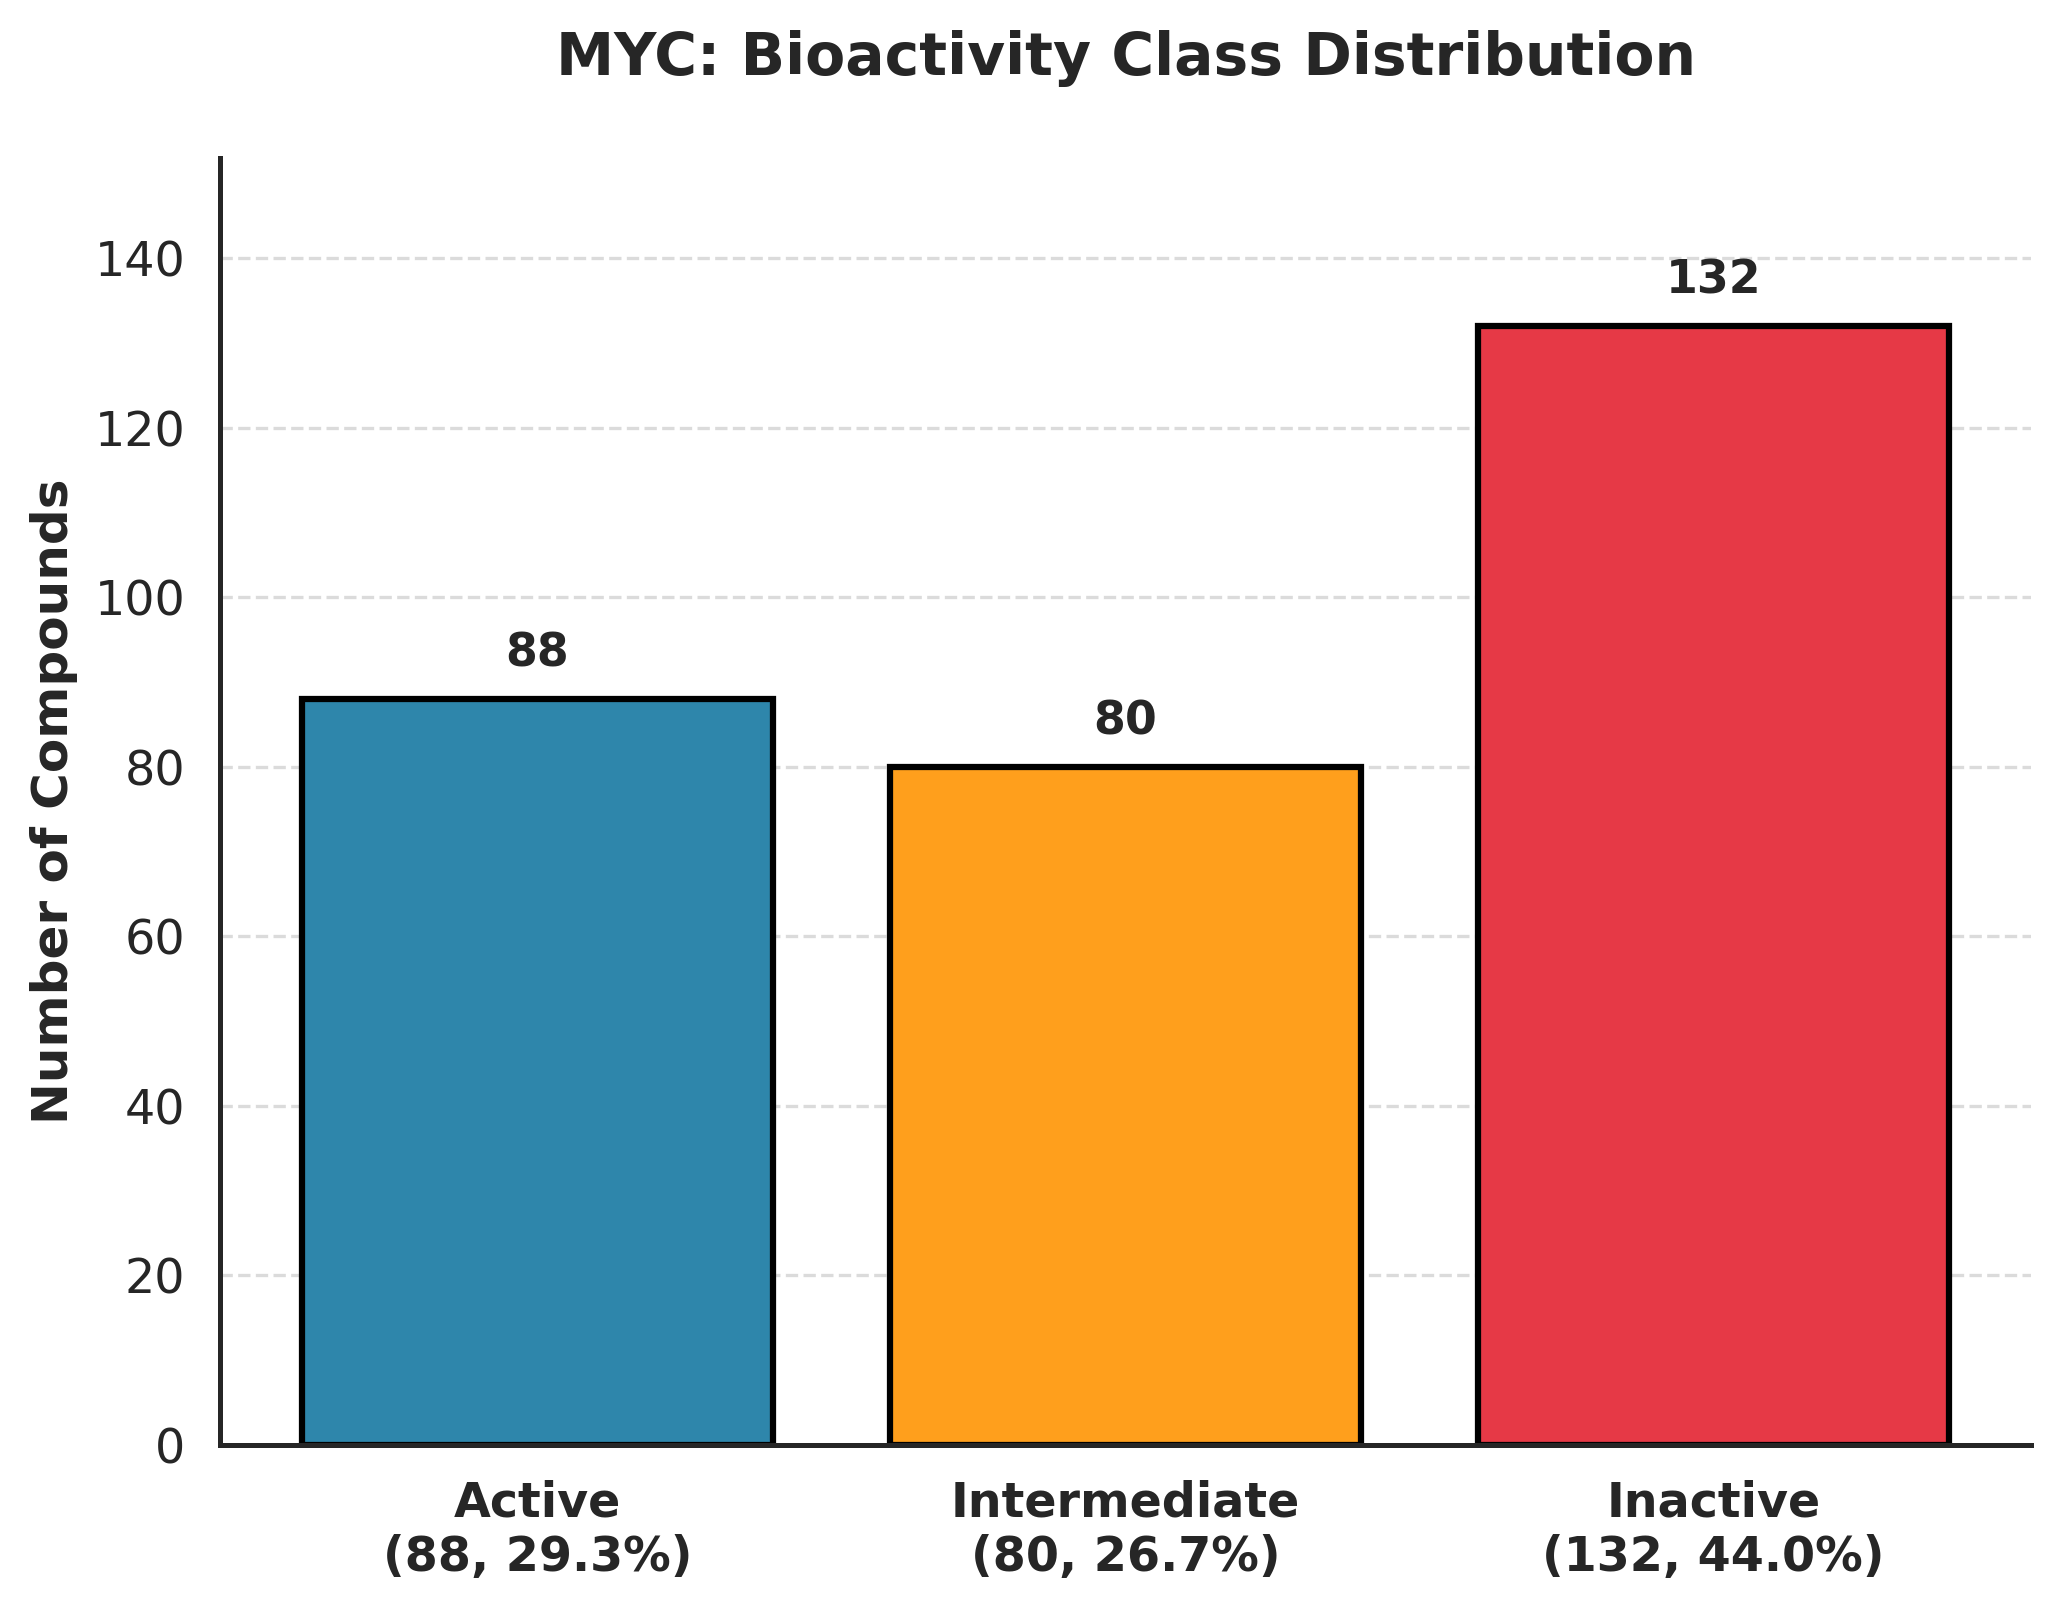

In [18]:
# @title # (A) Class distribution

from pathlib import Path

fig, ax = plt.subplots(figsize=(7, 5.5))
class_order = ["active", "intermediate", "inactive"]
colors = ["#2E86AB", "#FF9F1C", "#E63946"]

counts = []
labels = []
colors_used = []

for c, color in zip(class_order, colors):
    n = int((df_final["class"] == c).sum())
    if n > 0:
        pct = (n / len(df_final)) * 100
        counts.append(n)
        labels.append(f"{c.capitalize()}\n({n}, {pct:.1f}%)")
        colors_used.append(color)

bars = ax.bar(
    labels,
    counts,
    color=colors_used,
    edgecolor="black",
    linewidth=1.5
)

for bar in bars:
    h = bar.get_height()
    ax.text(
        bar.get_x() + bar.get_width()/2.,
        h + 0.02*max(counts),
        f"{int(h)}",
        ha="center",
        va="bottom",
        fontweight="bold"
    )

ax.set_ylabel("Number of Compounds", fontweight="bold")

ax.set_title(
    f"{OUTPUT_PREFIX}: Bioactivity Class Distribution",
    fontweight="bold",
    pad=20
)

ax.set_ylim(0, max(counts) * 1.15)
ax.yaxis.grid(True, linestyle="--", alpha=0.7)
ax.set_axisbelow(True)

sns.despine()

# Make X-axis labels bold
plt.setp(ax.get_xticklabels(), fontweight="bold")

# =====================================================
# SAVE TIFF (EXISTING FUNCTION)
# =====================================================

filename = f"{OUTPUT_PREFIX}_class_distribution_with_percentages"

tiff_result = save_tiff(fig, filename)

# =====================================================
# SAVE HIGH-QUALITY PNG IN THE SAME OUTPUT DIRECTORY
# =====================================================

tiff_path = None

# Use the returned TIFF path if available
if isinstance(tiff_result, (str, Path)):
    possible_path = Path(tiff_result)

    if (
        possible_path.is_file()
        and possible_path.suffix.lower() in (".tif", ".tiff")
    ):
        tiff_path = possible_path

# Otherwise locate the TIFF saved by the existing function
if tiff_path is None:
    matches = [
        path
        for ext in ("tif", "tiff")
        for path in Path.cwd().rglob(f"{filename}.{ext}")
        if path.is_file()
    ]

    if not matches:
        raise FileNotFoundError(
            "Saved TIFF not found under the current directory. "
            "Check the output path used by save_tiff()."
        )

    tiff_path = max(
        matches,
        key=lambda path: path.stat().st_mtime_ns
    )

# Save PNG beside TIFF
png_path = tiff_path.with_suffix(".png")

fig.savefig(
    png_path,
    format="png",
    dpi=600,
    bbox_inches="tight",
    facecolor="white"
)

print(f"PNG saved: {png_path}")

plt.show()

✅ Saved: PART2_OUTPUTS/MYC_MW_vs_LogP_chemical_space.tiff


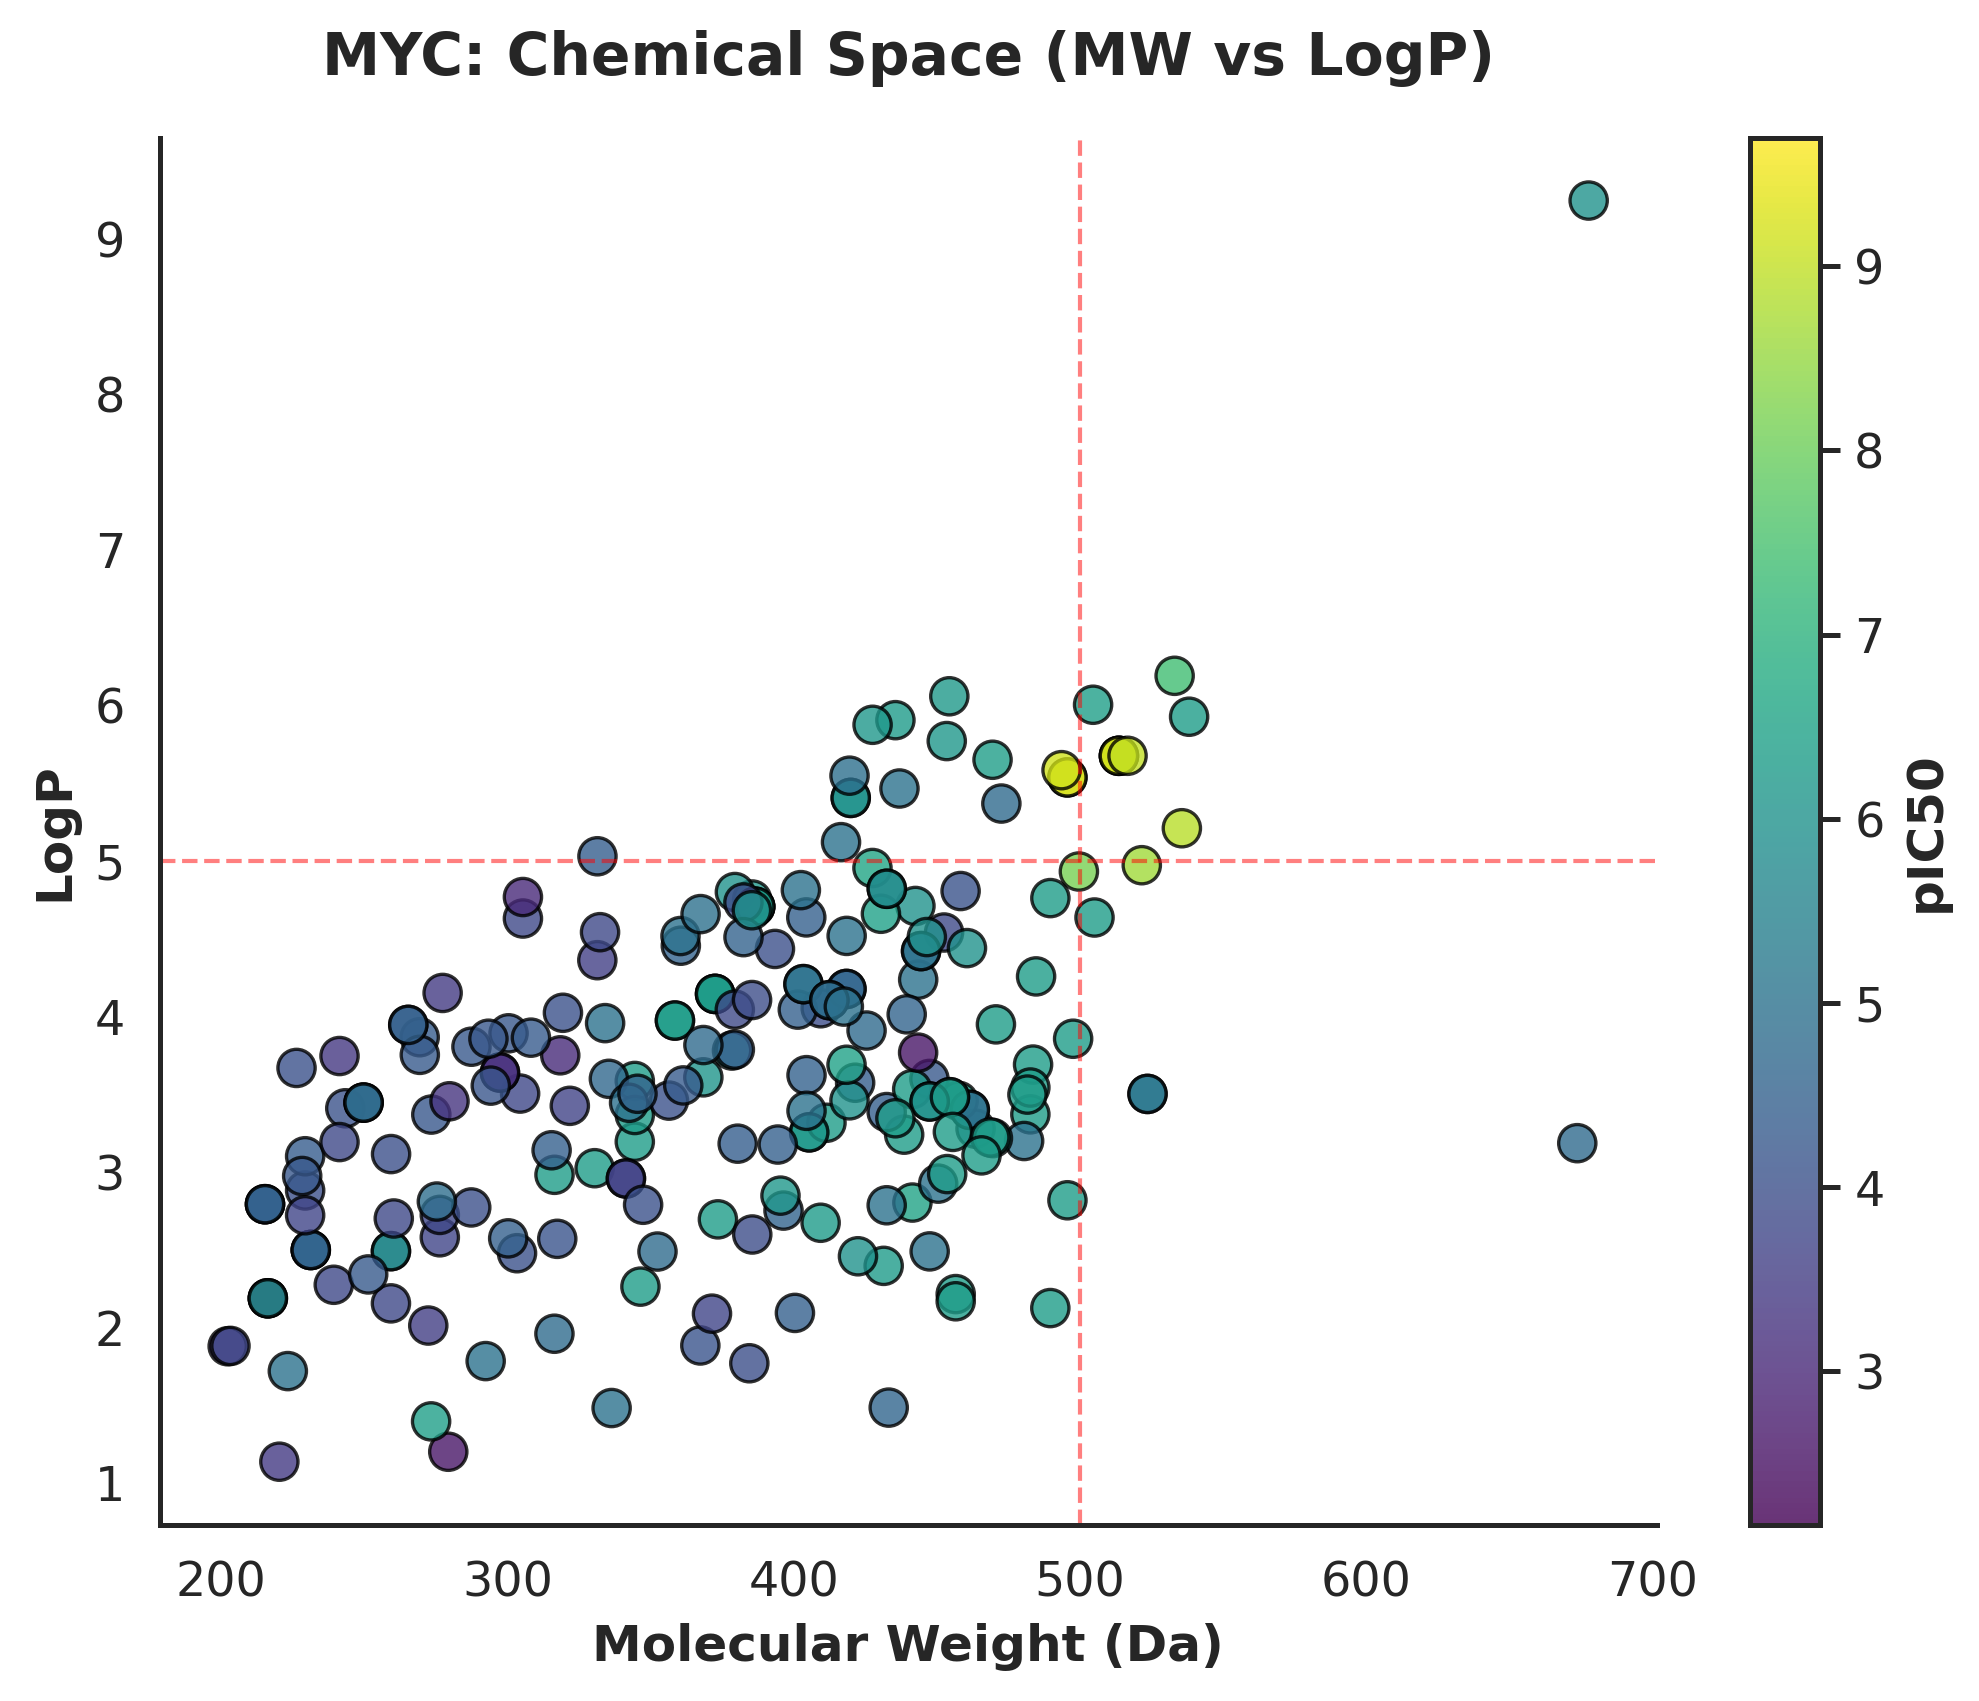

In [21]:
# @title # (B) MW vs LogP scatter ✅ fixed
plot_df = df_2class.replace([np.inf, -np.inf], np.nan).dropna(subset=["MW", "LogP", "pIC50"])
fig, ax = plt.subplots(figsize=(7, 5.8))

sc = ax.scatter(plot_df["MW"], plot_df["LogP"], c=plot_df["pIC50"],
                cmap="viridis", edgecolor="black", alpha=0.8, s=80)

ax.set_title(f"{OUTPUT_PREFIX}: Chemical Space (MW vs LogP)", fontweight="bold", pad=15)
ax.set_xlabel("Molecular Weight (Da)", fontweight="bold")
ax.set_ylabel("LogP", fontweight="bold")

cbar = plt.colorbar(sc, ax=ax)
cbar.set_label("pIC50", fontweight="bold")

ax.axhline(y=5, color="red", linestyle="--", alpha=0.5, linewidth=1)
ax.axvline(x=500, color="red", linestyle="--", alpha=0.5, linewidth=1)

sns.despine()
save_tiff(fig, f"{OUTPUT_PREFIX}_MW_vs_LogP_chemical_space")
plt.show()

/tmp/ipykernel_983/2132919374.py:11: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  box = ax.boxplot(


✅ Saved: PART2_OUTPUTS/MYC_pIC50_boxplot.tiff
PNG saved: PART2_OUTPUTS/MYC_pIC50_boxplot.png


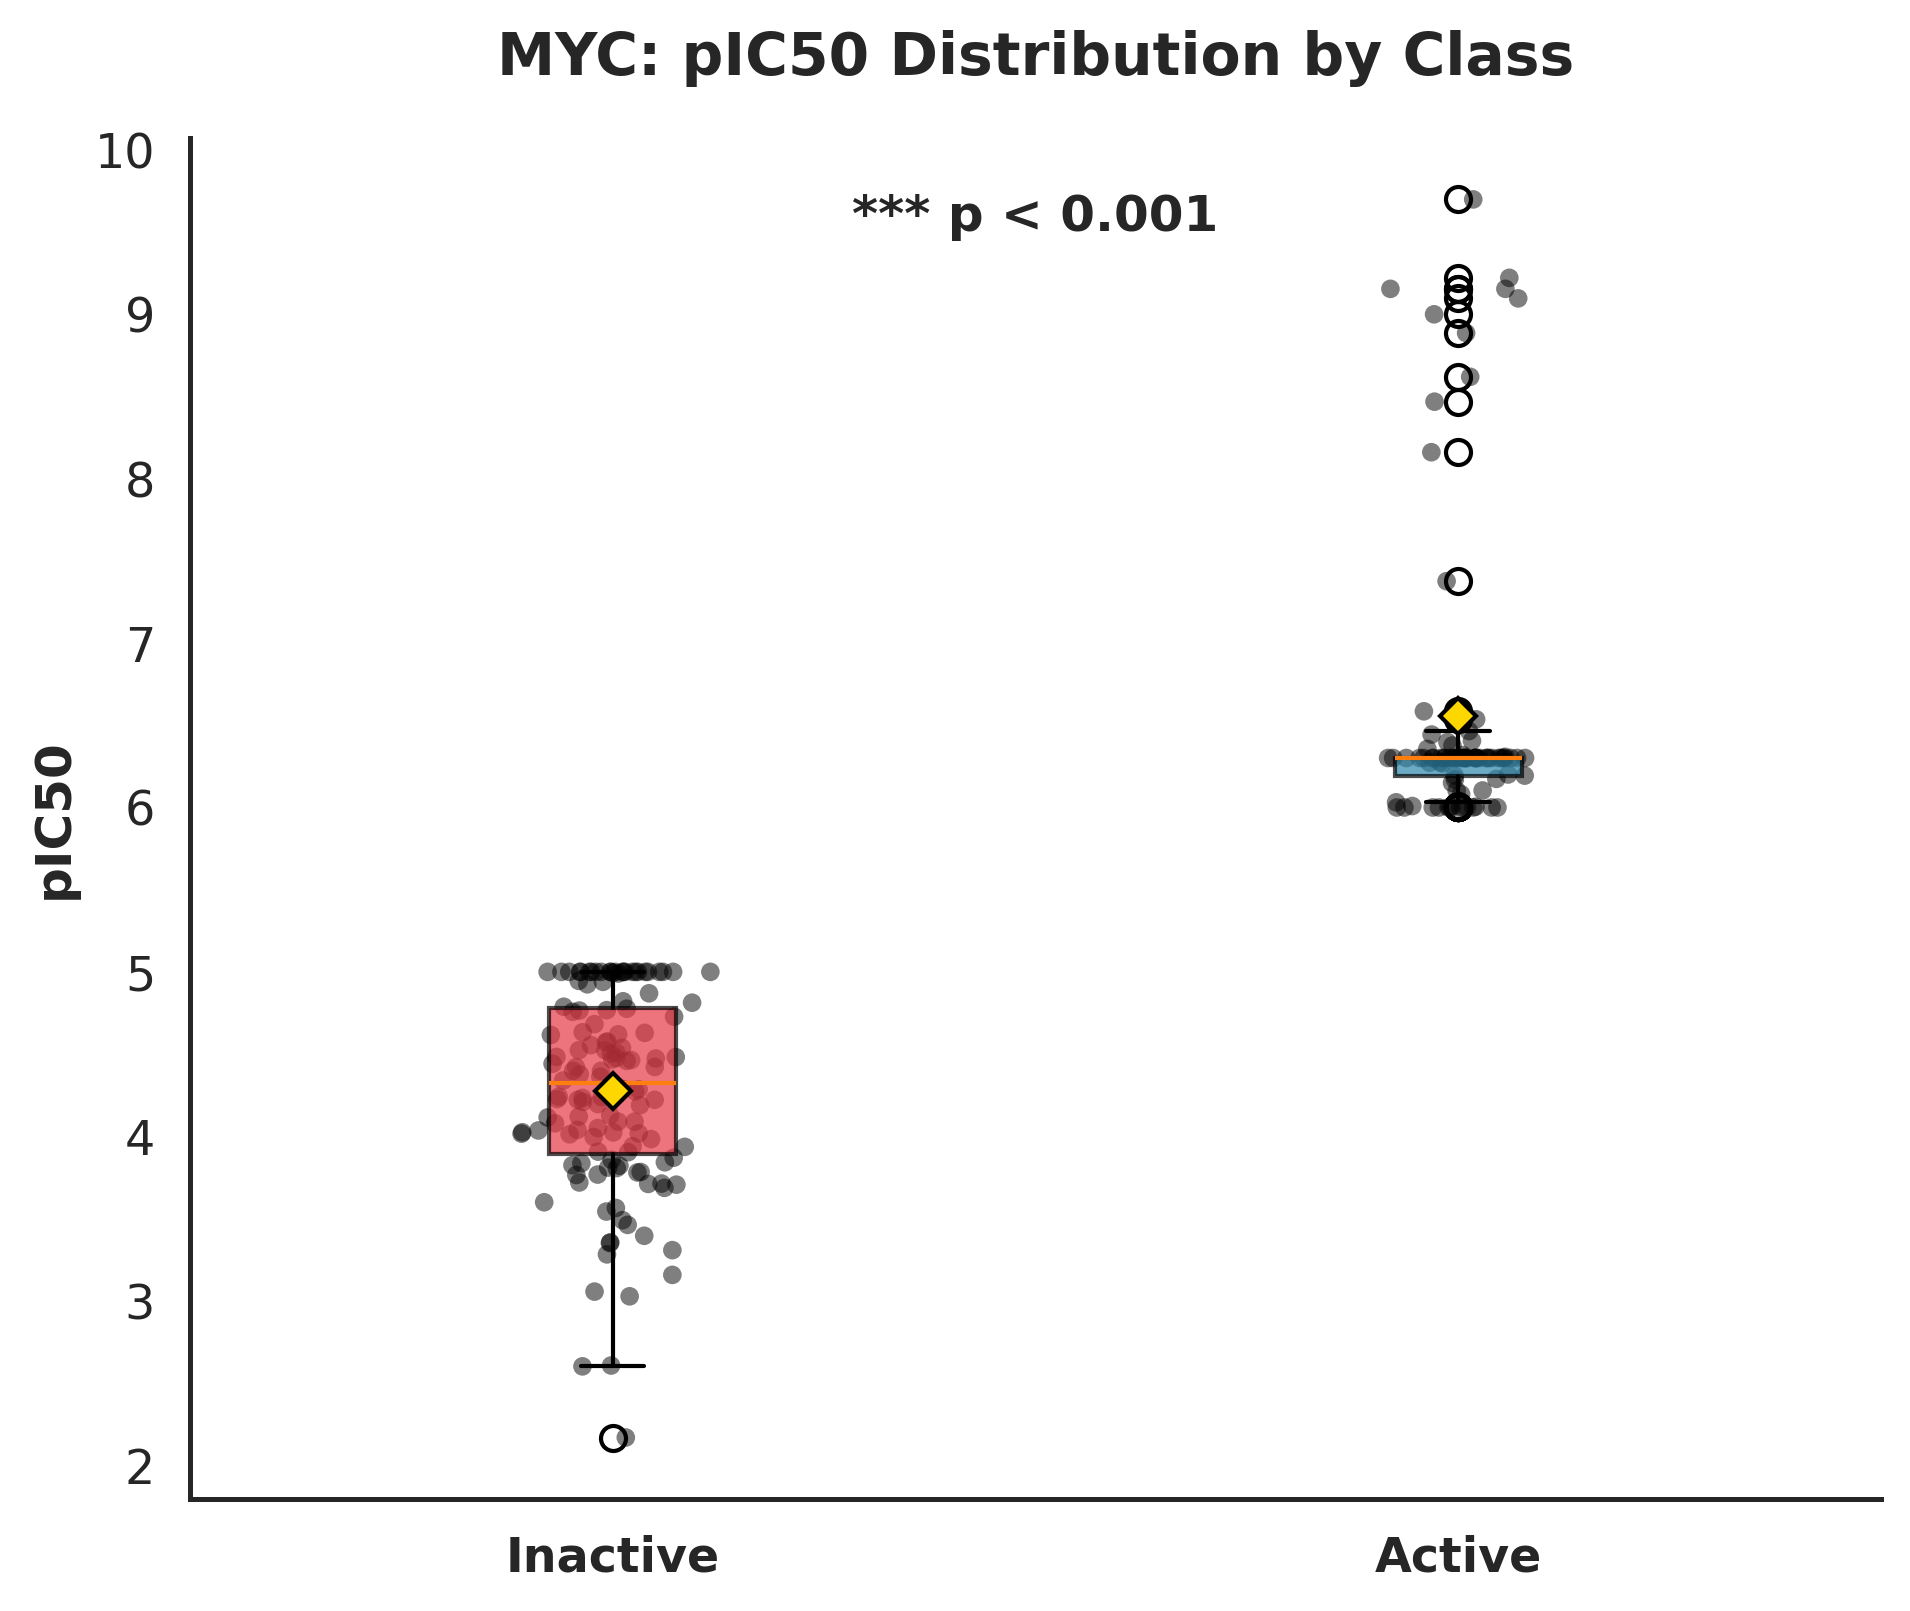

In [23]:
# @title # (C) pIC50 boxplot ✅ Mann–Whitney significance

from pathlib import Path

fig, ax = plt.subplots(figsize=(6.5, 5.5))

inactive = df_2class[df_2class["class"] == "inactive"]["pIC50"].dropna()
active   = df_2class[df_2class["class"] == "active"]["pIC50"].dropna()
box_data = [inactive, active]

box = ax.boxplot(
    box_data,
    labels=["Inactive", "Active"],
    patch_artist=True,
    showmeans=True,
    meanprops=dict(
        marker="D",
        markeredgecolor="black",
        markerfacecolor="gold"
    )
)

for patch, color in zip(box["boxes"], ["#E63946", "#2E86AB"]):
    patch.set_facecolor(color)
    patch.set_alpha(0.7)

for i, data in enumerate(box_data):
    x = np.random.normal(i + 1, 0.04, size=len(data))
    ax.scatter(
        x,
        data,
        alpha=0.5,
        s=20,
        color="black",
        edgecolor="none"
    )

ax.set_title(
    f"{OUTPUT_PREFIX}: pIC50 Distribution by Class",
    fontweight="bold",
    pad=15
)

ax.set_ylabel("pIC50", fontweight="bold")

# Make X-axis labels bold
plt.setp(ax.get_xticklabels(), fontweight="bold")

if len(inactive) >= 5 and len(active) >= 5:
    U, p_val = mannwhitneyu(
        inactive,
        active,
        alternative="two-sided"
    )

    if p_val < 0.001:
        sig_text = "*** p < 0.001"
    elif p_val < 0.01:
        sig_text = "** p < 0.01"
    elif p_val < 0.05:
        sig_text = "* p < 0.05"
    else:
        sig_text = "ns"

    ymax = max(inactive.max(), active.max())

    ax.text(
        1.5,
        ymax * 0.98,
        sig_text,
        ha="center",
        fontweight="bold",
        fontsize=12
    )

sns.despine()

# =====================================================
# SAVE TIFF (EXISTING FUNCTION)
# =====================================================

filename = f"{OUTPUT_PREFIX}_pIC50_boxplot"

tiff_result = save_tiff(fig, filename)

# =====================================================
# SAVE HIGH-QUALITY PNG IN THE SAME OUTPUT DIRECTORY
# =====================================================

tiff_path = None

# If save_tiff returns the saved TIFF path
if isinstance(tiff_result, (str, Path)):
    possible_path = Path(tiff_result)

    if (
        possible_path.is_file()
        and possible_path.suffix.lower() in (".tif", ".tiff")
    ):
        tiff_path = possible_path

# Otherwise search for the TIFF file
if tiff_path is None:
    matches = [
        path
        for ext in ("tif", "tiff")
        for path in Path.cwd().rglob(f"{filename}.{ext}")
        if path.is_file()
    ]

    if not matches:
        raise FileNotFoundError(
            "Saved TIFF not found under the current directory. "
            "Check the output path used by save_tiff()."
        )

    tiff_path = max(
        matches,
        key=lambda path: path.stat().st_mtime_ns
    )

# Save PNG beside TIFF
png_path = tiff_path.with_suffix(".png")

fig.savefig(
    png_path,
    format="png",
    dpi=600,
    bbox_inches="tight",
    facecolor="white"
)

print(f"PNG saved: {png_path}")

plt.show()

✅ Saved: PART2_OUTPUTS/MYC_lipinski_descriptors.tiff
PNG saved: PART2_OUTPUTS/MYC_lipinski_descriptors.png


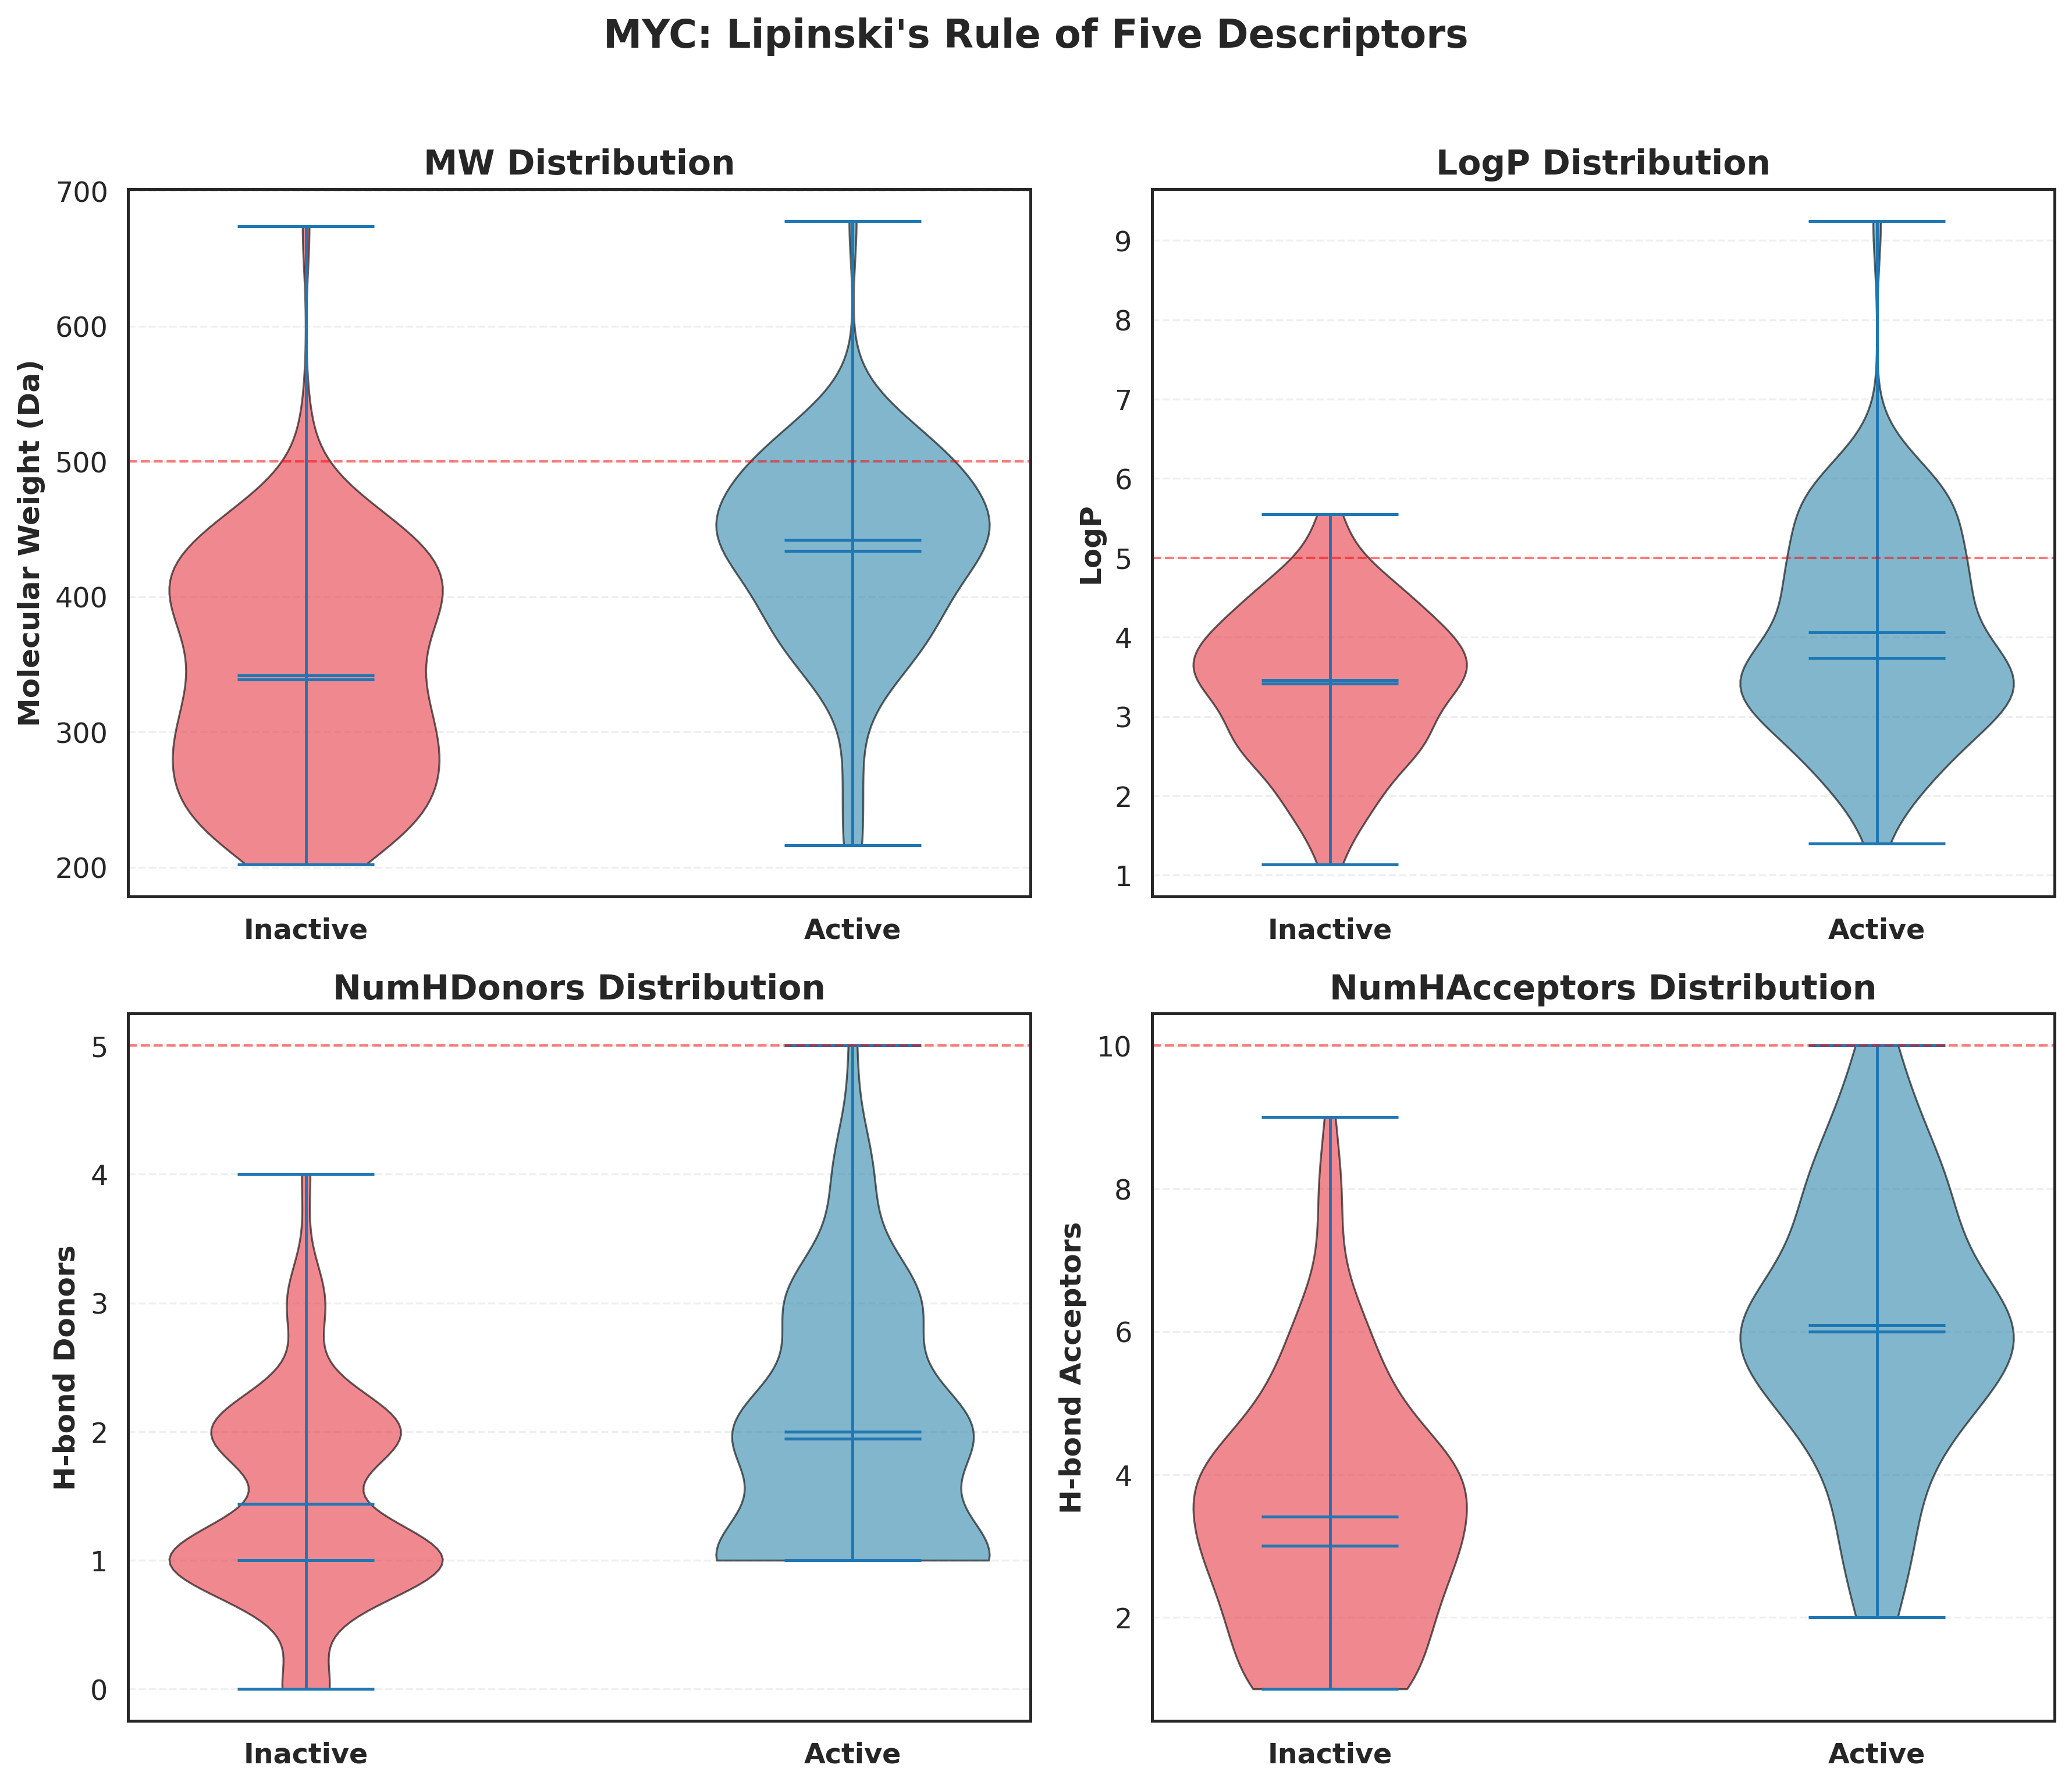

In [24]:
# @title # (D) Lipinski violins

from pathlib import Path

fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.flatten()

lip_cols = ["MW", "LogP", "NumHDonors", "NumHAcceptors"]
lip_limits = [500, 5, 5, 10]
lip_names = ["Molecular Weight (Da)", "LogP", "H-bond Donors", "H-bond Acceptors"]

for idx, (col, limit, name) in enumerate(zip(lip_cols, lip_limits, lip_names)):
    ax = axes[idx]

    violin = ax.violinplot(
        [
            df_2class[df_2class["class"] == "inactive"][col].dropna(),
            df_2class[df_2class["class"] == "active"][col].dropna()
        ],
        showmeans=True,
        showmedians=True
    )

    for pc, color in zip(violin["bodies"], ["#E63946", "#2E86AB"]):
        pc.set_facecolor(color)
        pc.set_alpha(0.6)
        pc.set_edgecolor("black")

    ax.set_xticks([1, 2])
    ax.set_xticklabels(["Inactive", "Active"])
    ax.set_ylabel(name, fontweight="bold")
    ax.set_title(f"{col} Distribution", fontweight="bold")
    ax.yaxis.grid(True, linestyle="--", alpha=0.3)

    # Make X-axis labels bold
    plt.setp(ax.get_xticklabels(), fontweight="bold")

    if limit is not None:
        ax.axhline(
            y=limit,
            color="red",
            linestyle="--",
            alpha=0.5,
            linewidth=1
        )

fig.suptitle(
    f"{OUTPUT_PREFIX}: Lipinski's Rule of Five Descriptors",
    fontweight="bold",
    fontsize=16,
    y=1.02
)

plt.tight_layout()

# =====================================================
# SAVE TIFF (EXISTING FUNCTION)
# =====================================================

filename = f"{OUTPUT_PREFIX}_lipinski_descriptors"

tiff_result = save_tiff(fig, filename)

# =====================================================
# SAVE HIGH-QUALITY PNG IN THE SAME OUTPUT DIRECTORY
# =====================================================

tiff_path = None

# If save_tiff returns the saved TIFF path
if isinstance(tiff_result, (str, Path)):
    possible_path = Path(tiff_result)

    if (
        possible_path.is_file()
        and possible_path.suffix.lower() in (".tif", ".tiff")
    ):
        tiff_path = possible_path

# Otherwise search for the TIFF file
if tiff_path is None:
    matches = [
        path
        for ext in ("tif", "tiff")
        for path in Path.cwd().rglob(f"{filename}.{ext}")
        if path.is_file()
    ]

    if not matches:
        raise FileNotFoundError(
            "Saved TIFF not found under the current directory. "
            "Check the output path used by save_tiff()."
        )

    tiff_path = max(
        matches,
        key=lambda path: path.stat().st_mtime_ns
    )

# Save PNG beside TIFF
png_path = tiff_path.with_suffix(".png")

fig.savefig(
    png_path,
    format="png",
    dpi=600,
    bbox_inches="tight",
    facecolor="white"
)

print(f"PNG saved: {png_path}")

plt.show()

In [26]:
# @title Step 15: Mann–Whitney tests + effect size (rank-biserial)
# ==========================================================
print("\n🔬 Mann–Whitney U tests (active vs inactive) ...")
mw_results = []
for col in ["pIC50", "MW", "LogP", "NumHDonors", "NumHAcceptors"]:
    mw_results.append(mann_whitney_test(df_2class, col, class_col="class"))

mw_df = pd.concat(mw_results, ignore_index=True)
mw_path = os.path.join("PART2_OUTPUTS", f"{OUTPUT_PREFIX}_mannwhitney_results.csv")
mw_df.to_csv(mw_path, index=False)
print(f"✅ Saved: {mw_path}")
display(mw_df)


🔬 Mann–Whitney U tests (active vs inactive) ...
✅ Saved: PART2_OUTPUTS/MYC_mannwhitney_results.csv


,Descriptor,U_statistic,p_value,alpha,Interpretation,n_active,n_inactive,Effect_size_rank_biserial
0,pIC50,11616.0,2.0916e-36,0.05,Significantly different (p ≤ 0.05),88,132,-1.000
1,MW,9371.5,1.3242e-14,0.05,Significantly different (p ≤ 0.05),88,132,-0.614
2,LogP,7399.0,5.8434e-04,0.05,Significantly different (p ≤ 0.05),88,132,-0.274
3,NumHDonors,7398.0,2.1926e-04,0.05,Significantly different (p ≤ 0.05),88,132,-0.274
4,NumHAcceptors,9899.0,4.4284e-19,0.05,Significantly different (p ≤ 0.05),88,132,-0.704


In [27]:
# @title Step 16: Summary (Just run)
import os

# Ensure the output directory exists
os.makedirs("PART2_OUTPUTS", exist_ok=True)

# Define the path for the combined text report
report_filename = f"{OUTPUT_PREFIX}_summary_report.txt"
report_path = os.path.join("PART2_OUTPUTS", report_filename)

print(f"\n📝 Compiling summary reports into: {report_path}")

with open(report_path, "w") as f:
    f.write(f"--- Combined Summary Report for {OUTPUT_PREFIX} ---\n\n")

    # Write Final Curation Flow
    f.write("### 📈 Final Curation Flow ###\n")
    # The 'flow' variable was updated throughout the notebook, so we'll use the latest one
    final_flow_df = pd.DataFrame(flow, columns=["Step", "Count"])
    f.write(final_flow_df.to_string(index=False))
    f.write("\n\n")

    # Write Class Statistics
    f.write("### Class Statistics ###\n")
    f.write(class_stats.to_string(index=False))
    f.write("\n\n")

    # Write Mann-Whitney Test Results
    f.write("### 🔬 Mann–Whitney U tests (active vs inactive) ###\n")
    f.write(mw_df.to_string(index=False))
    f.write("\n\n")

    f.write(f"--- End of Report for {OUTPUT_PREFIX} ---\n")

print(f"✅ All summary reports saved to: {report_path}")


📝 Compiling summary reports into: PART2_OUTPUTS/MYC_summary_report.txt
✅ All summary reports saved to: PART2_OUTPUTS/MYC_summary_report.txt


In [28]:
# @title Step 17: Zip + download outputs
# ==========================================================
import zipfile
from google.colab import files

zip_name = os.path.join("PART2_OUTPUTS", f"{OUTPUT_PREFIX}_Part2_outputs.zip")
files_to_zip = [fn for fn in os.listdir("PART2_OUTPUTS") if fn.startswith(OUTPUT_PREFIX)]

if files_to_zip:
    with zipfile.ZipFile(zip_name, "w", compression=zipfile.ZIP_DEFLATED) as z:
        for fn in files_to_zip:
            z.write(os.path.join("PART2_OUTPUTS", fn), arcname=fn)

    print(f"\n✅ Created: {zip_name}")
    files.download(zip_name)
else:
    print("⚠️ No output files found to zip.")

print("\n🎉 Part-2 completed. Next: Part-3.1 (descriptor generation)")



✅ Created: PART2_OUTPUTS/MYC_Part2_outputs.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


🎉 Part-2 completed. Next: Part-3.1 (descriptor generation)


# USER MANUAL & QUICK START GUIDE
## PART 2 — Per-Gene/Target Data Curation and Exploratory Data Analysis (EDA)
### ChEMBL IC50 Bioactivity | RDKit Molecular Descriptors | Publication-Oriented Figures

DEVELOPER INFORMATION
Developed by: Md Fazlay Rabbi
Affiliation: Department of Rajshahi, University of Rajshahi, Bangladesh
Email: rabbi.ms244@gmail.com

======================================================================
1. OVERVIEW

======================================================================

This Google Colab notebook prepares target-specific ChEMBL IC50
bioactivity data for subsequent cheminformatics and machine-learning
workflows. Users can identify a protein target using its UniProt accession,
select the appropriate ChEMBL target, clean and standardize bioactivity
records, calculate molecular descriptors, explore chemical properties,
and download organized output files.

The notebook is designed for ONE selected gene/protein target per run.
No local input CSV is needed for the primary workflow; records are
retrieved through the online ChEMBL API.

MAIN WORKFLOW
UniProt accession -> ChEMBL target selection -> IC50 retrieval ->
Data cleaning -> SMILES standardization -> Duplicate aggregation ->
pIC50 transformation -> Activity classification -> Molecular descriptors
-> EDA and statistical comparisons -> Downloadable results

==============================================

2. BEFORE YOU START

===============================================

Requirements:
- A Google account and access to Google Colab.
- A working internet connection for downloading packages and ChEMBL data.
- A valid UniProtKB accession for your target of interest.
- Basic familiarity with running notebook cells in sequence.

The notebook installs/uses Python libraries such as:
chembl_webresource_client, RDKit, pandas, NumPy, SciPy, Matplotlib,
Seaborn, tqdm and IPython/Google Colab utilities.

IMPORTANT: This version uses Google Colab-specific interactive elements.
For the intended experience, open it in Google Colab rather than running
it unchanged in a generic local Jupyter environment.

===================================================

3. QUICK START: HOW TO RUN THE NOTEBOOK

====================================================

1) Upload/open the .ipynb file in Google Colab and connect to a runtime.

2) Execute Step 1 (package installation), Step 2 (plot settings), and
   Step 3 (ChEMBL API preparation).

3) In Step 4, enter your UniProt accession into the target-search panel.
   Example accessions shown in the notebook:
   - P00533 (EGFR)
   - P15056 (BRAF)
   - P00519 (ABL1)
   Click "Search Targets," review the numbered ChEMBL target results,
   enter the preferred row number, and click "Retrieve IC50 Bioactivities."
   Confirm that the selected ChEMBL ID matches your intended target.
   The optional "Download all compounds CSV" button exports the
   compound-list preview data and is not required to run later cells.

4) Run Step 5 AFTER selecting the ChEMBL target. Check the automatically
   detected target details, enter a clear gene/target name (for example,
   EGFR), then click "Save Configuration." This sets the output file
   prefix and confirms the target for downstream analysis.

5) Execute Step 6 (helper functions).

6) Run Steps 7 through 13 IN ORDER to retrieve, curate, transform,
   describe and save the target-specific compounds. Check the printed
   data counts and tables after each processing step.

7) Run Step 14's four EDA plotting cells (A-D), followed by Step 15
   (statistical comparisons) and Step 16 (combined summary report).

8) Finally, run Step 17 to create and download the ZIP archive of
   generated output files.

Do not skip the target-selection or configuration actions. Later cells
rely on variables created by the previous cells. If the runtime restarts,
start again from Step 1 and repeat the interactive selections.

=============================================

4. WHAT EACH NOTEBOOK STEP DOES

=================================================


Step 1  | Installs the main Python packages.
Step 2  | Sets figure styles and defines a high-resolution TIFF saver.
Step 3  | Initializes the ChEMBL API clients.
Step 4  | Searches ChEMBL with a UniProt ID; selects a target; displays
        | IC50 binding-assay record and distinct compound counts.
Step 5  | Detects the selected ChEMBL ID; sets the target name,
        | activity thresholds and safe filename prefix.
Step 6  | Defines SMILES processing, pIC50, descriptor, class-statistics
        | and Mann-Whitney comparison functions.
Step 7  | Downloads target-specific IC50 records from ChEMBL.
Step 8  | Keeps relevant columns; filters units/relations; excludes
        | missing, nonnumeric or nonpositive IC50 values and SMILES.
Step 9  | Keeps the largest SMILES fragment and generates canonical SMILES.
Step 10 | Combines repeated canonical SMILES using median IC50 values.
Step 11 | Converts IC50 (nM) to pIC50 and assigns activity classes.
Step 12 | Calculates molecular weight, LogP, H-bond donors and acceptors.
Step 13 | Exports curated data tables, class summaries and curation flow.
Step 14 | Creates class-distribution, MW-vs-LogP, pIC50 and Lipinski plots.
Step 15 | Performs Mann-Whitney U comparisons between active and inactive
        | compounds and reports rank-biserial effect-size values.
Step 16 | Writes a combined plain-text summary report.
Step 17 | Packages target-prefixed results into a ZIP file and downloads it.

=============================================

5. IMPORTANT DATA-PROCESSING RULES

===============================================


- Bioactivity type: IC50.
- Accepted standard units in the final curation: nM ONLY.
- Accepted standard relations in the final curation: "=" or missing.
- IC50 values must be valid positive numbers; molecular SMILES must exist.
- Structures are standardized by selecting the largest fragment and
  canonicalizing SMILES with RDKit.
- Duplicate standardized structures are aggregated by median IC50.
- pIC50 = -log10(IC50 in molar units), after applying the configured cap.

DEFAULT CLASSIFICATION THRESHOLDS
- Active:       IC50 <= 1,000 nM
- Intermediate: 1,000 nM < IC50 < 10,000 nM
- Inactive:     IC50 >= 10,000 nM
- IC50 upper cap for pIC50 conversion: 100,000,000 nM (1e8 nM)

These values are defined in Step 5. If your research protocol requires
different cutoffs, review and update them BEFORE processing the data.
Document any changed thresholds when sharing your results.

NOTE ON RECORD COUNTS: Step 4's preview specifically counts records
with IC50, an exact relation ("=") and binding assay type ("B").
Step 7 retrieves a broader IC50 set; Step 8 then performs its own
relation/unit filtering. Therefore, the preview counts and the final
curation counts may differ. Treat them as different stages, not as
necessarily inconsistent results.

=========================================

6. OUTPUTS: WHAT YOU WILL GET

=======================================


Files are stored in the folder:
PART2_OUTPUTS/

<GENE> below means the sanitized uppercase target-name prefix that
was entered and saved in Step 5 (for example, EGFR).

CORE CSV OUTPUTS
- <GENE>_regression_ALL.csv
  Full curated table, including active, intermediate and inactive records.

- <GENE>_classification_2class.csv
  Binary classification table: active and inactive only; excludes
  intermediate compounds.

- <GENE>_class_statistics.csv
  Class counts, percentages, pIC50 summaries and IC50 ranges.

- <GENE>_curation_flow.csv
  Record counts at each main cleaning and deduplication stage.

- <GENE>_mannwhitney_results.csv
  Mann-Whitney U-test results and rank-biserial effect sizes for pIC50,
  MW, LogP, H-bond donors and H-bond acceptors.

OTHER OUTPUTS
- <GENE>_summary_report.txt
  Combined curation-flow, class-statistics and test-results report.

- <GENE>_Part2_outputs.zip
  Downloadable archive of the generated files for that target prefix.

EDA FIGURES
- Activity class-distribution plot
- Molecular-weight versus LogP chemical-space scatter plot
- pIC50 distribution boxplot for active versus inactive compounds
- Lipinski-descriptor violin plots

The notebook saves high-resolution TIFF figures. In the actual code,
class distribution, pIC50 boxplot and Lipinski plots ALSO save PNG files;
the MW-vs-LogP plot uses the TIFF helper without a separate PNG save.
Thus, the introductory "TIFF only" note in the notebook does not fully
reflect the current plotting-cell behavior.

============================================

7. HOW TO INTERPRET THE RESULTS

=============================================


- Regression dataset: Contains continuous pIC50 activity values and
  molecular properties, suitable as a starting point for later modeling.
- Classification dataset: Contains only the two extreme activity groups,
  useful for binary classification after further modeling checks.
- Curation flow: Shows where records were lost during filtering and
  standardization; inspect these counts to understand data coverage.
- MW/LogP and Lipinski plots: Show broad molecular-property patterns.
- Mann-Whitney results: Describe differences between the active and
  inactive groups; statistical significance is not proof of biological
  importance, predictive power or clinical usefulness.

Since activity classes are defined from IC50 itself, a pIC50 difference
between those classes is expected by construction. Do not interpret that
particular test as independent validation of a predictive model.

For publication or downstream model development, independently review
assay comparability, source records, structures, class balance,
duplicates, data leakage, and any limitations of the selected target.

=======================================

8. TROUBLESHOOTING

=======================================


Problem: No ChEMBL targets appear.
Action: Verify the UniProt accession, internet access and ChEMBL coverage.

Problem: "No selected target found" in Step 5.
Action: Complete Step 4's target selection and IC50 retrieval, then rerun
Step 5 and save the configuration.

Problem: An output prefix or target variable is missing.
Action: Check that Step 5's "Save Configuration" was successful and
that earlier cells have run in the correct order.

Problem: Final dataset is empty or very small.
Action: Review Step 8 filtering, nM availability, missing SMILES,
failed canonicalization and the curation-flow table. Do not fabricate
or manually fill activity values to force the notebook to run.

Problem: The API request is slow or fails.
Action: Confirm network access; retry the failed stage after checking
service availability. Large target datasets can require longer requests.

Problem: EDA or statistical cells fail with small/empty classes.
Action: Check the final active/inactive group sizes. The separate
Mann-Whitney helper reports insufficient samples below three per class;
the pIC50 boxplot only annotates significance when each group has at
least five records. Some plots may need manual handling of empty groups.

Problem: Files are missing after a runtime disconnect.
Action: Google Colab runtime storage is temporary. Download your ZIP
before ending the session. Rerun the full workflow after a reset.

========================================

9. RESPONSIBLE RESEARCH USE

==========================================


This tool supports exploratory research and reproducible data curation;
it does not establish drug efficacy, target validation, compound safety,
or clinical outcomes. Verify ChEMBL records and follow applicable
research, reporting, database-attribution and licensing requirements.

When comparing targets, perform a separate workflow for each target,
retain its ChEMBL and UniProt identifiers, and document filtering rules.
The exact number of retrieved activities may change as ChEMBL is updated.

===========================================

DEVELOPER & CONTACT

===========================================

Developed by: Md Fazlay Rabbi
Affiliation: Department of Rajshahi, University of Rajshahi, Bangladesh
Email: rabbi.ms244@gmail.com


======================================================================